# RSNA Knee Abnormality Detection: обучение на Mac (MPS)

Вторая версия пайплайна. Учит модель на Mac через видеокарту Apple (MPS). Данные: «сырой» кэш из
`03_build_cache_kaggle.ipynb`, по одному файлу на колено. Вся подготовка примеров происходит в классе `Dataset`.

## Задача

По МРТ колена предсказать 12 находок (разрыв связок и менисков, артроз трёх отделов, выпот, синовит, киста
Бейкера, ушиб кости, перелом). Метрика: **macro-AUC**, то есть AUC по каждой из 12 находок, потом среднее.
AUC смотрит только на **порядок** предсказаний: больные должны получить числа выше, чем здоровые.

## Как устроен весь проект

| Ноутбук | Где | Что делает |
|---|---|---|
| `03_build_cache_kaggle.ipynb` | Kaggle, CPU | DICOM -> `studies/<ID>.npz`: все срезы выбранных серий по порядку, 224 px, 140 мм |
| `05_pack_cache_kaggle.ipynb` | Kaggle, CPU | упаковывает часть кэша в один файл для скачивания |
| `01_baseline_dinov2.ipynb` | Mac | первый бейзлайн (0.64, точка отсчёта) |
| **`02_report_labels_mil.ipynb`** | **Mac, MPS** | **учит модель, пишет веса в `outputs/weights`** |
| `04_kaggle_submission.ipynb` | Kaggle, GPU | веса -> `submission.csv` |

## Матрёшка данных

```
1 колено = 1 файл data/raw/studies/<ID>.npz
└── до 6 ящиков (slot0 ... slot5) = 3 плоскости (сбоку, спереди, сверху) × 2 режима (с подавлением жира и без)
    └── в каждом ящике 1 серия
        └── в серии 12-32 среза (картинки 224×224, по порядку в теле)
```

Всё связано по ID колена (`StudyInstanceUID`): по нему ищется строка в `train.csv` (текст врача и метки)
и файл со снимками.

## Кто что делает

| Где | Что |
|---|---|
| билдер (03) | всё, для чего нужны заголовки DICOM: выбор серий, порядок срезов, ориентация, кроп в мм |
| **`Dataset` (раздел 5)** | **заполнение пустых ящиков, зеркало колена, выбор окон из срезов, аугментации, нормализация** |
| `DataLoader` | собирает колена в батчи; 6 процессов готовят следующий батч, пока видеокарта считает |
| модель (раздел 6) | картинки -> векторы -> внимание по окнам -> 12 логитов |

## Разделы ноутбука

| # | Раздел | Что внутри |
|---|---|---|
| 0 | Конфиг | все настройки в одном месте |
| 1 | Таблицы | `train.csv`, тексты заключений, какие серии нашлись |
| 2 | Сырые данные | файл одного колена и карта данных на картинках |
| 3 | Метки из текстов | экстрактор: текст врача -> мягкие метки для всех 4407 колен |
| 4 | `Y`, `W`, фолды | метки, веса, деление на части |
| 5 | Dataset | как из файла колена получается пример; какие срезы берут окна |
| 6 | Модель | энкодер DINOv2 + внимание по окнам |
| 7 | Инструменты | ranking loss, EMA, предсказание, метрика |
| 8 | Обучение | цикл обучения и разбор прогона |
| 9 | Что дальше | сабмит и улучшения |

## Почему первая версия стояла на 0.55-0.64

В `train.csv` 12 меток заполнены только у **58 из 4407** колен, у остальных `NaN`. `np.nan_to_num(labels, nan=0.0)`
превращал 98.7% данных в «здоров по всем 12 находкам». Здесь метки берутся из текстов заключений (раздел 3).
Первый прогон этого ноутбука (фолд 0): **gold 0.809**.

## Импорты

| Импорт | Зачем |
|---|---|
| `os`, `sys`, `gc`, `time`, `json`, `Path` | служебное: пути, память, время, файлы настроек |
| `hashlib` | хэш текста заключения для деления на фолды (раздел 4) |
| `textwrap` | красиво печатать длинные тексты |
| `deepcopy` | копия модели для EMA (раздел 7) |
| `numpy`, `pandas`, `matplotlib` | массивы, таблицы, картинки |
| `torch`, `nn`, `F` | PyTorch: тензоры, слои, функции (лоссы, `softplus`) |
| `timm` | готовые модели; отсюда энкодер DINOv2 |
| `roc_auc_score` | метрика соревнования |
| `DataLoader` | собирает примеры `Dataset` в батчи, умеет готовить их в нескольких процессах |

`OMP_NUM_THREADS` и похожие ограничивают потоки математических библиотек, чтобы 6 воркеров `DataLoader`
не дрались за ядра процессора.

`DEV` - устройство для расчётов: `mps` (видеокарта Apple Silicon) или `cpu`.

In [2]:
import os                                               # работа с ОС: пути, переменные окружения, список файлов
# сколько потоков могут занимать математические библиотеки; setdefault - только если не задано раньше
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "4")                      # задать переменную окружения, если её ещё нет

import gc                                               # сборщик мусора: gc.collect() освобождает память между фолдами
import math                                             # математика (math.radians и т.п.)
import time                                             # time.time() - текущее время в секундах
import json                                             # чтение и запись файлов JSON
import hashlib                                          # хэши (md5)
import textwrap                                         # перенос длинного текста по ширине
import warnings                                         # управление предупреждениями библиотек
import sys                                              # sys: путь к Python и sys.path (где искать модули)
from copy import deepcopy                               # полная копия объекта
from pathlib import Path                                # пути: Path("a") / "b" склеивает части пути

import numpy as np                                      # массивы чисел и математика над ними
import pandas as pd                                     # таблицы (DataFrame): чтение csv, фильтры, группировки
import matplotlib.pyplot as plt                         # рисование картинок и графиков
import torch                                            # PyTorch: тензоры, видеокарта, обучение
import torch.nn as nn                                   # слои нейросетей и nn.Module
import torch.nn.functional as F            # функции без весов: лоссы, softplus, grid_sample
import timm                                             # готовые модели (DINOv2)
from sklearn.metrics import roc_auc_score               # AUC - метрика соревнования
from torch.utils.data import DataLoader                 # собирает примеры Dataset в батчи

warnings.filterwarnings("ignore")          # не засорять вывод предупреждениями библиотек
T0 = time.time()                           # время старта: log() печатает секунды от него

def log(msg):
    # печать с отметкой времени: [   12.3s] сообщение. :7.1f - 7 знаков ширины, 1 после запятой
    print(f"[{time.time() - T0:7.1f}s] {msg}", flush=True)

try:                                                    # попробовать; ошибку перехватит except
    display                                # в Jupyter display красиво рисует таблицы
except NameError:                                       # имени display нет (запуск вне Jupyter)
    display = print                                     # тогда display - это обычный print

# Устройство: видеокарта Apple Silicon через MPS, иначе процессор.
# torch.device(...) - объект устройства; у него есть .type ("mps" / "cpu"), он нужен ниже
DEV = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
log(f"устройство: {DEV}, torch {torch.__version__}, timm {timm.__version__}")  # устройство и версии библиотек

[    0.0s] устройство: mps, torch 2.8.0, timm 1.0.30


## 0. Конфиг

Все настройки в одном месте. Меняйте **одну** ручку за раз и смотрите на `gold` в логе обучения.
`IMG`, `CROP_MM` и `MAX_SLICES` здесь не задаются: они читаются из `rsna_raw_meta.json` (раздел 2),
то есть такие, с какими собран кэш.

| Группа | Параметр | Значение | Что значит |
|---|---|---|---|
| Энкодер | `BACKBONE` | ViT-S DINOv2 | 2D-сеть, которая превращает одну картинку в вектор из 384 чисел |
| | `WEIGHTS_PATH` | `None` | `None` - timm скачает веса сам; можно указать путь к `.pth` |
| | `UNFREEZE_LAST` | 6 | сколько последних блоков ViT (из 12) учится. Ранние блоки - общие «детекторы краёв», их не трогаем |
| Dataset | `K_WIN` | 4 | окон из каждого ящика при проверке (фиксированные) |
| | `K_TRAIN` | 2 | окон при обучении (случайные каждую эпоху) |
| | `WIN_BAND` | (0.08, 0.92) | окна ставятся между 8% и 92% длины стопки срезов |
| | `FILL_MISSING_SLOTS` | `True` | пустой ящик заполняется парой из той же плоскости |
| | `MIRROR_P` | 0.5 | вероятность зеркала колена (левое <-> правое) при обучении |
| | `AUG` | см. код | поворот, зум, сдвиг, контраст, яркость |
| Метки | `GOLD_IN_TRAIN` | `False` | 58 размеченных вручную не учим, на них честная проверка |
| Голова | `HIDDEN` | 256 | длина векторов внутри головы |
| | `TF_DEPTH` | 1 | слоёв трансформера, через которые окна «переговариваются» |
| Обучение | `N_FOLDS` / `FOLDS_TO_RUN` | 4 / `[0]` | на сколько частей делим данные / какие модели учим |
| | `EPOCHS` | 10 | сколько раз проходим все обучающие колена |
| | `BATCH_STUDIES` | 8 | колен в одном шаге обучения |
| | `LR_BACKBONE` / `LR_HEAD` | 8e-6 / 5e-4 | шаг обучения энкодера (только подстраиваем) и головы (учится с нуля) |
| | `WEIGHT_DECAY` | 0.02 | тянет веса к нулю: мягкая защита от переобучения |
| | `PCT_START` | 0.15 | первые 15% шагов LR растёт (разогрев), потом плавно падает до 0 |
| | `EMA_DECAY` | 0.997 | сглаживание весов: модель для проверки = среднее весов за ~300 последних шагов |
| | `RANK_LOSS_W` | 0.05 | вес ranking loss, который напрямую тянет AUC |
| | `USE_AMP` | на MPS | половинная точность float16: шаг примерно в 1.5 раза быстрее |
| | `TTA_MIRROR` | `True` | на проверке смотрим на колено и на его зеркало, усредняем |
| | `NUM_WORKERS` | 6 | сколько процессов готовят батчи параллельно с обучением |

**`FOLDS_TO_RUN` и `N_FOLDS`.** `N_FOLDS = 4` делит колена на 4 части. Фолд `k` = модель, которая учится на трёх
частях и проверяется на части `k`. `FOLDS_TO_RUN = [0]` учит одну такую модель (~1 час), `[0, 1, 2, 3]` - все четыре,
их предсказания потом усредняются (ансамбль).

In [3]:
SEED = 2026                # зерно случайности: тот же SEED -> те же случайные числа при каждом запуске

# ---------------- Папки ----------------
# Ноутбук запускается из папки rsna-knee-abnormality-detection.
DATA_DIR = Path.cwd() / "data" / "raw"    # сырой кэш: studies/, index_part*.csv, rsna_raw_meta.json, train.csv
STUDY_DIR = DATA_DIR / "studies"          # по файлу на исследование
OUT_DIR = Path.cwd() / "outputs"                        # Path.cwd() - текущая папка ноутбука
WEIGHTS_DIR = OUT_DIR / "weights"         # сюда пишутся веса фолдов
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)          # создать папку весов, если её нет
for _p in (STUDY_DIR, DATA_DIR / "train.csv", DATA_DIR / "rsna_raw_meta.json"):  # проверяем, что данные на месте
    assert _p.exists(), f"нет {_p}: распакуйте части кэша в data/raw/"  # нет файла -> понятная ошибка сразу

# ---------------- Энкодер (2D-сеть, которая смотрит на одну картинку) ----------------
BACKBONE = "vit_small_patch14_dinov2.lvd142m"   # DINOv2 ViT-S, 22M параметров
WEIGHTS_PATH = None        # путь к .pth с весами; None: timm скачает их из интернета сам
UNFREEZE_LAST = 6          # сколько последних блоков ViT учится (из 12). Ранние блоки - общие
                           # «детекторы краёв»: данных мало, испортить их легко

# ---------------- Как Dataset готовит пример ----------------
K_WIN = 4                  # окон на серию при проверке: фиксированные, равномерно в полосе WIN_BAND
K_TRAIN = 2                # окон на серию при обучении: случайные каждую эпоху (быстрее и работает как аугментация)
WIN_BAND = (0.08, 0.92)    # окна ставятся от 8% до 92% стека срезов: края - мягкие ткани вне сустава
FILL_MISSING_SLOTS = True  # нет серии с fat-sat -> подставить серию той же плоскости без него (и наоборот)
MIRROR_P = 0.5             # с вероятностью 50% «зеркалим колено» (левое <-> правое) при обучении
AUG = dict(rot_deg=10.0,   # поворот ±10°
           scale=0.10,     # зум внутрь до +10%
           shift=0.06,     # сдвиг ±6%
           gamma=0.25,     # контраст (гамма)
           gain=0.10)      # яркость ±10%

# ---------------- Метки ----------------
GOLD_IN_TRAIN = False      # False: 58 размеченных НЕ участвуют в обучении, на них честная проверка

# ---------------- Модель (голова над энкодером) ----------------
HIDDEN = 256               # размер векторов в голове
TF_DEPTH = 1               # слоёв трансформера, через которые окна «переговариваются» (0 = выключить)

# ---------------- Обучение ----------------
N_FOLDS = 4                # на сколько частей делим данные (по хэшу текста заключения, раздел 4)
FOLDS_TO_RUN = [0]         # какие части учить: каждая = отдельная модель. Итоговый вариант: [0, 1, 2, 3]
EPOCHS = 10                                             # сколько раз проходим все обучающие колена
BATCH_STUDIES = 8          # исследований в батче (каждое = до 6 серий × K_TRAIN окон)
LR_BACKBONE = 8e-6         # энкодер только «подстраиваем»: большой LR разрушит предобучение
LR_HEAD = 5e-4             # голова учится с нуля, ей нужен LR намного больше
WEIGHT_DECAY = 0.02        # AdamW тянет веса к нулю на 2% от LR за шаг: защита от переобучения
PCT_START = 0.15           # первые 15% шагов LR плавно растёт (разогрев), потом падает до нуля
EMA_DECAY = 0.997          # «скользящее среднее» весов, сглаживает шум (0 = выключить)
RANK_LOSS_W = 0.05         # вес ранжирующего лосса (напрямую тянет AUC вверх)
RANK_POS, RANK_NEG = 0.60, 0.40   # мягкая метка > 0.6 - «есть», < 0.4 - «нет» (для ranking loss)
USE_AMP = DEV.type == "mps"       # смешанная точность float16: на MPS шаг примерно в 1.5 раза быстрее
AMP_DTYPE = torch.float16                               # тип половинной точности
TTA_MIRROR = True          # на проверке усредняем обычный и зеркальный вид
EVAL_BATCH = 4             # исследований за раз при предсказании
NUM_WORKERS = 6            # сколько процессов DataLoader готовят батчи параллельно с обучением

# 12 целей: в этом порядке идут колонки train.csv, выходы модели и колонки сабмита
TARGETS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",  # 12 целей в порядке колонок сабмита
           "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
           "Contusion", "Fracture"]


def seed_everything(seed):
    # одно зерно всем генераторам случайности: Python, NumPy, PyTorch (и на MPS)
    import random                                       # случайные числа стандартной библиотеки Python
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)  # зерно для random, numpy и torch
    if DEV.type == "mps":                               # только на видеокарте Apple
        torch.mps.manual_seed(seed)                     # зерно генератора MPS


def empty_device_cache():
    # отдать системе память видеокарты, которую PyTorch держит «про запас» (между фолдами)
    if DEV.type == "mps":                               # только на видеокарте Apple
        torch.mps.empty_cache()                         # вернуть системе неиспользуемую память MPS


seed_everything(SEED)                                   # применить зерно
log(f"данные: {DATA_DIR}, веса фолдов: {WEIGHTS_DIR}")  # напечатать пути

[    0.1s] данные: /Users/admin/Desktop/kaggle-deep-learning/rsna-knee-abnormality-detection/data/raw, веса фолдов: /Users/admin/Desktop/kaggle-deep-learning/rsna-knee-abnormality-detection/outputs/weights


## 1. Таблицы

### 1.1 `train.csv`: одна строка = одно колено

Колонки: `StudyInstanceUID` (ID колена), `Report` (текст заключения врача) и 12 целей.
Смотрите на колонки целей: сколько в них **пустых** значений. Это и есть главный вывод: ручная разметка
есть только у 58 колен.

`gold_mask_df` - серия из True/False длиной 4407: True, если у колена заполнены все 12 меток.

In [4]:
train_df = pd.read_csv(DATA_DIR / "train.csv")          # таблица: строка = колено
print("размер:", train_df.shape, "  колонки:", list(train_df.columns))  # .shape = (строк, колонок)
display(train_df.drop(columns=["Report"]).head(5))          # без длинного текста, чтобы таблица влезла

# .notna() - True там, где не NaN; .all(axis=1) - True, если True во всех 12 колонках строки
gold_mask_df = train_df[TARGETS].notna().all(axis=1)      # True, если все 12 меток заполнены
print(f"\n Исследований с РУЧНОЙ разметкой всех 12 меток: {int(gold_mask_df.sum())} из {len(train_df)}")  # sum() по True/False = число True
print(f"   У остальных {int((~gold_mask_df).sum())} метки пустые (NaN). В v1 они стали нулями - отсюда 0.55.\n")  # ~ - логическое НЕ для колонки

cnt = pd.DataFrame({"заполнено": train_df[TARGETS].notna().sum(),  # таблица: сколько заполнено и пусто по каждой цели
                    "пусто (NaN)": train_df[TARGETS].isna().sum(),
                    "доля «есть» среди размеченных": train_df.loc[gold_mask_df, TARGETS].mean().round(2)})
display(cnt)                                            # показать таблицу

размер: (4407, 14)   колонки: ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



 Исследований с РУЧНОЙ разметкой всех 12 меток: 58 из 4407
   У остальных 4349 метки пустые (NaN). В v1 они стали нулями - отсюда 0.55.



,заполнено,пусто (NaN),доля «есть» среди размеченных
ACL,58,4349,0.41
MCL,58,4349,0.16
Medial Meniscus,58,4349,0.45
Lateral Meniscus,58,4349,0.40
Medial OA,58,4349,0.26
Lateral OA,58,4349,0.19
PF OA,58,4349,0.36
Effusion,58,4349,0.60
Synovitis,58,4349,0.47
Baker's,58,4349,0.21


### 1.2 Тексты заключений (`Report`) - настоящий источник меток

Заключения на разных языках (английский, испанский, турецкий, греческий, болгарский и др.).
Именно из них в разделе 3 мы сделаем метки для всех 4407 колен. Ниже: начала 12 случайных текстов и один
полный текст вместе с ручными метками этого колена, чтобы было видно, как текст соотносится с метками.

In [5]:
rep = train_df["Report"].fillna("")            # пустой текст вместо NaN
print(f"длина заключения в символах: медиана {int(rep.str.len().median())}, "  # .str.len() - длина каждого текста
      f"min {rep.str.len().min()}, max {rep.str.len().max()}\n")

print("Начала 12 случайных заключений (видно, какие языки):")  # заголовок
for t in rep.sample(12, random_state=0):        # random_state=0: каждый раз те же 12
    print("  •", t.replace("\n", " ")[:110])            # переводы строк -> пробелы, первые 110 символов

print("\n" + "=" * 100)                                 # "=" * 100 - строка из 100 знаков "="
ex = train_df[gold_mask_df].iloc[0]             # первое размеченное колено
print("Пример ПОЛНОГО заключения у размеченного исследования и его ручные метки:\n")  # заголовок
print(textwrap.fill(ex["Report"][:1500], 110))  # перенос строк по 110 символов
print("\nручные метки:", {t: int(ex[t]) for t in TARGETS})  # словарь {цель: 0 или 1}

длина заключения в символах: медиана 977, min 52, max 4743

Начала 12 случайных заключений (видно, какие языки):
  • ΤΕΧΝΙΚΗ: Η εξέταση πραγµατοποιήθηκε µε ακολουθίες PD µε καταστολή του σήµατος του λίπους, Τ1 και Τ2*. ΕΥΡΗΜΑΤΑ
  • SAĞ DİZ MRG. Tetkik protokolü: Çok düzlemli, çok sekanslı. Bulgular: Lateral menisküs anterior ve posterior ho
  • MRI ∆ΕΞΙΟΥ ΓΟΝΑΤΟΣ ΤΕΧΝΙΚΗ Η εξέταση έγινε µε ακολουθίες παλµών Τ1 και πυκνότητας πρωτονίων µε καταστολή του σ
  • SAĞ DİZ MRG. Tetkik protokolü: Çok düzlemli, çok sekanslı. Bulgular: Lateral menisküs normaldir.  Medial menis
  • Antecedentes Clínicos: Síndrome meniscal medial. Hallazgos: No hay alteraciones de señal significativas de la 
  • FINDINGS:  Fluid: No joint effusion. No popliteal cyst. Small popliteal ganglion cyst.  Medial compartment (me
  • No evidence of knee effusion. Normal medial and lateral menisci. No evidence of tears.  Normal ACL, PCL, MCL a
  • Lig. iliotibiale postoperativ zunehmend verdickt von zuletzt 3 auf 6 mm (5/14)

### 1.3 Какие серии нашлись (`index_part*.csv`)

Справка от билдера: **одна строка = одна серия, положенная в ящик**. Колонки: `slot` (номер ящика 0-5),
`slot_name`, `SeriesInstanceUID`, `plane`, `n_files` (сколько было файлов `.dcm`), `n_slices_saved`
(сколько срезов сохранено, не больше 32).

Таблица ниже: у какой доли колен есть каждый ящик. Чаще всего пустует `AX_NOFS` (сверху без подавления жира).

In [6]:
# обе части индекса в одну таблицу; ignore_index - пронумеровать строки заново
INDEX = pd.concat([pd.read_csv(p) for p in sorted(DATA_DIR.glob("index_part*.csv"))], ignore_index=True)
display(INDEX.head())                                   # первые 5 строк индекса
n_studies = train_df["StudyInstanceUID"].nunique()      # число разных колен
# для каждого ящика: сколько разных колен его имеют / всего колен
cov = (INDEX.groupby(["slot", "slot_name"])["StudyInstanceUID"].nunique() / n_studies).round(3)
display(cov.rename("доля исследований").to_frame())     # дать имя колонке и показать таблицей
print(f"серий на исследование: в среднем {INDEX.groupby('StudyInstanceUID').size().mean():.2f}")  # сколько строк индекса у колена в среднем
print("срезов в сохранённой серии:", INDEX["n_slices_saved"].describe()[["min", "50%", "mean", "max"]].round(1).to_dict())  # describe - статистика колонки; 50% = медиана

,StudyInstanceUID,slot,slot_name,SeriesInstanceUID,plane,n_files,n_slices_saved
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,0,SAG_FS,1.2.826.0.1.3680043.8.498.12343110195036213483...,Sagittal,22,22
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1,COR_FS,1.2.826.0.1.3680043.8.498.40734206102458723096...,Coronal,16,16
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,2,AX_FS,1.2.826.0.1.3680043.8.498.13821229744997220641...,Axial,18,18
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,3,SAG_NOFS,1.2.826.0.1.3680043.8.498.75714899997203615784...,Sagittal,22,22
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,4,COR_NOFS,1.2.826.0.1.3680043.8.498.23084836536722595275...,Coronal,16,16


,,доля исследований
slot,slot_name,
0,SAG_FS,0.942
1,COR_FS,0.964
2,AX_FS,1.000
3,SAG_NOFS,0.968
4,COR_NOFS,0.773
5,AX_NOFS,0.194


серий на исследование: в среднем 4.84
срезов в сохранённой серии: {'min': 12.0, '50%': 30.0, 'mean': 28.4, 'max': 32.0}


## 2. Сырые данные: файл одного колена

Файл `studies/<ID>.npz` - словарь массивов: ключи `slot0`...`slot5`, только для найденных серий.
Каждый массив - все срезы серии **по порядку в теле**: `[n_срезов, 224, 224]`, тип `uint8` (яркость 0..255).

Сначала читаем `rsna_raw_meta.json`: с какими настройками собран кэш (`IMG = 224`, `CROP_MM = 140`, `MAX_SLICES = 32`).
Эти числа пойдут в модель и в файлы весов.

Берём размеченное колено (`STUDY`), чтобы рядом видеть его метки. На картинке строка = серия (ящик),
столбцы = 5 срезов равномерно по стопке, от края до края.

[    0.2s] кэш собран с IMG=224, CROP_MM=140.0, MAX_SLICES=32
  slot0: (32, 224, 224) uint8, яркость 0..255
  slot1: (30, 224, 224) uint8, яркость 0..255
  slot2: (32, 224, 224) uint8, яркость 0..255
  slot3: (32, 224, 224) uint8, яркость 0..255
  slot4: (30, 224, 224) uint8, яркость 0..255


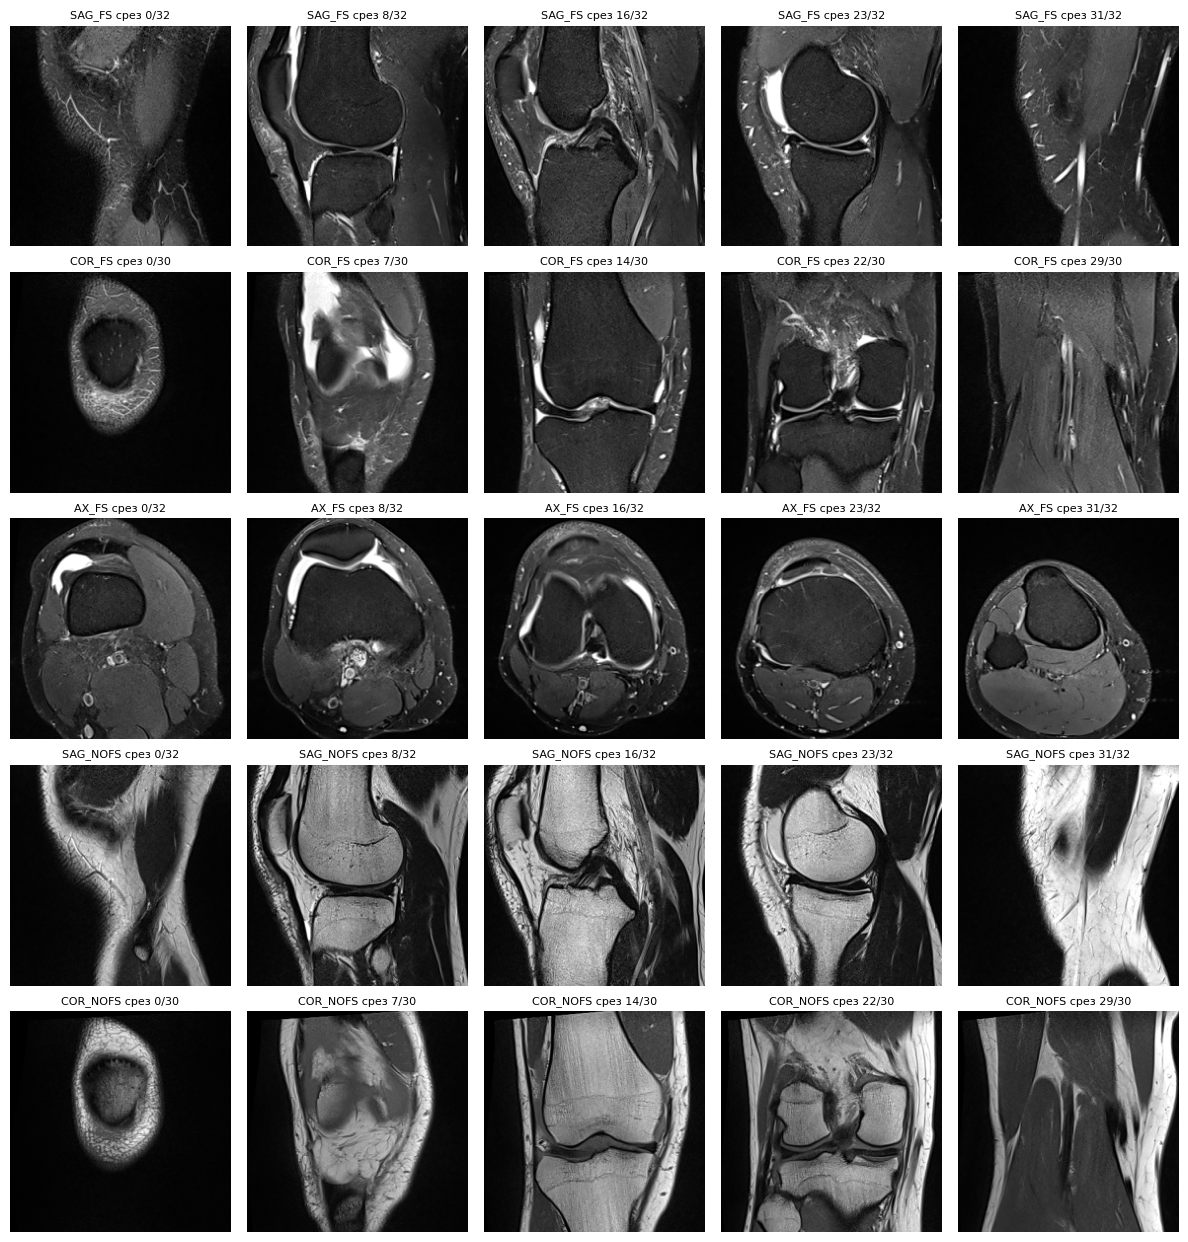

In [7]:
with open(DATA_DIR / "rsna_raw_meta.json") as fh:       # открыть файл на чтение; закроется сам
    META = json.load(fh)                                # словарь настроек билдера
IMG, CROP_MM, MAX_SLICES = META["IMG"], META["CROP_MM"], META["MAX_SLICES"]  # три настройки кэша
log(f"кэш собран с IMG={IMG}, CROP_MM={CROP_MM}, MAX_SLICES={MAX_SLICES}")  # напечатать их

STUDY = train_df.loc[gold_mask_df, "StudyInstanceUID"].iloc[0]    # размеченное, чтобы видеть метки
with np.load(STUDY_DIR / f"{STUDY}.npz") as z:          # z.files = ["slot0", "slot1", ...]
    RAW = {key: z[key] for key in sorted(z.files)}       # {"slot0": [n, 224, 224], ...} в памяти
for key, s in RAW.items():                              # .items() - пары (ключ, значение)
    print(f"  {key}: {s.shape} {s.dtype}, яркость {s.min()}..{s.max()}")  # форма, тип и диапазон яркости ящика

SLOT_NAMES = ["SAG_FS", "COR_FS", "AX_FS", "SAG_NOFS", "COR_NOFS", "AX_NOFS"]  # имена ящиков по номеру
fig, axes = plt.subplots(len(RAW), 5, figsize=(12, 2.5 * len(RAW)))  # строка на ящик, 5 картинок в строке
for row, (key, s) in zip(np.atleast_2d(axes), RAW.items()):  # atleast_2d: даже при одном ящике axes будет таблицей
    # 5 номеров срезов равномерно от 0 до n-1
    for ax, j in zip(row, np.linspace(0, len(s) - 1, 5).round().astype(int)):
        ax.imshow(s[j], cmap="gray"); ax.axis("off")    # срез j серым, без осей
        ax.set_title(f"{SLOT_NAMES[int(key[4:])]} срез {j}/{len(s)}", fontsize=8)  # подпись: ящик и номер среза
plt.tight_layout(); plt.show()                          # убрать наложения и показать

### 2.1 Карта данных на одном колене

То же колено, разложенное по уровням матрёшки:

1. **Колено с трёх сторон**: средний срез каждой плоскости. Каждая сторона - отдельная серия.
2. **Серия = стопка срезов**, как нарезанный батон: 8 срезов одной серии от одного края колена до другого.
3. **Одна сторона, два режима**: с подавлением жира (FS: жир тёмный, жидкость светится - видны отёки и выпот)
   и без (NOFS: жир светлый, лучше видна анатомия). Поэтому ящиков 6 = 3 стороны × 2 режима.
4. **Окно = 3 соседних среза -> одна «цветная» картинка** (каналы R, G, B). Её и видит нейросеть.

In [ ]:
def show(ax, img, title):                               # показать картинку на оси ax с подписью
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)  # 2D - серая, 3D (цветная) - как есть
    ax.set_title(title, fontsize=9); ax.axis("off")     # подпись и без осей


# 1. три стороны: для каждой плоскости ящик с FS, если есть, иначе без
PLANE_PAIRS = [("сбоку (Sagittal)", 0, 3), ("спереди (Coronal)", 1, 4), ("сверху (Axial)", 2, 5)]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))       # 3 картинки в ряд
for ax, (name, a, b) in zip(axes, PLANE_PAIRS):         # ось и (название, ящик FS, ящик NOFS)
    key = f"slot{a}" if f"slot{a}" in RAW else f"slot{b}" if f"slot{b}" in RAW else None  # FS, иначе NOFS, иначе None
    if key is None:                                     # этой плоскости нет совсем
        ax.axis("off"); ax.set_title(f"{name}: нет серии", fontsize=9); continue  # пустая клетка; continue - к следующей
    s = RAW[key]                                        # стопка ящика
    show(ax, s[len(s) // 2], f"{name}\n{key} = {SLOT_NAMES[int(key[4:])]}, срезов: {len(s)}")  # средний срез
fig.suptitle("1. Колено = до 6 серий; здесь по одной на каждую сторону", fontsize=11, weight="bold")  # общий заголовок, жирный
plt.tight_layout(); plt.show()                          # убрать наложения и показать

# 2. одна серия = стопка срезов по порядку
SER = next((k for k in ("slot0", "slot3") if k in RAW), next(iter(RAW)))   # сагиттальная, если есть
s = RAW[SER]                                            # стопка выбранной серии
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))       # 8 картинок в ряд
for ax, j in zip(axes, np.linspace(0, len(s) - 1, 8).round().astype(int)):  # 8 номеров срезов равномерно
    show(ax, s[j], f"срез {j}")                         # срез j
fig.suptitle(f"2. Серия {SER} = массив {list(s.shape)}: срезы {IMG}x{IMG} по порядку через колено, всего {len(s)}",  # заголовок с формой массива
             fontsize=11, weight="bold")
plt.tight_layout(); plt.show()                          # убрать наложения и показать

# 3. FS против NOFS: первая плоскость, где есть оба режима
pair = next(((a, b) for _, a, b in PLANE_PAIRS if f"slot{a}" in RAW and f"slot{b}" in RAW), None)
present = [SLOT_NAMES[int(k[4:])] for k in RAW]         # имена ящиков, которые есть
missing = [n for n in SLOT_NAMES if n not in present]   # имена пустых ящиков
if pair is not None:                                    # нашлась плоскость с обоими режимами
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.8))    # 2 картинки
    for ax, k, note in zip(axes, pair, ["жир тёмный, жидкость светится", "жир светлый, видна анатомия"]):  # ось, ящик и пояснение
        st = RAW[f"slot{k}"]                            # стопка ящика k
        show(ax, st[len(st) // 2], f"slot{k} {SLOT_NAMES[k]}\n{note}")  # средний срез
    fig.suptitle("3. Одна сторона, два режима", fontsize=11, weight="bold")  # заголовок
    plt.tight_layout(); plt.show()                      # убрать наложения и показать
print(f"у этого колена ящики: {present}; пустые: {missing or 'нет'}. "  # пустой список -> "нет"
      f"Пустые Dataset заполнит парой из той же плоскости (FILL_MISSING_SLOTS = {FILL_MISSING_SLOTS})")

# 4. окно: 3 соседних среза из середины серии -> 3 канала одной картинки
c = len(s) // 2
win = s[c - 1:c + 2]                                    # [3, 224, 224]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))       # 3 среза и итоговое окно
for ax, j, ch in zip(axes[:3], range(c - 1, c + 2), "RGB"):  # срезы c-1, c, c+1 и буквы каналов
    show(ax, s[j], f"срез {j} -> канал {ch}")           # срез и его канал
show(axes[3], np.stack(win, -1), f"окно [3, {IMG}, {IMG}]\n(цвет = различие соседних срезов)")  # stack(..., -1): [3,H,W] -> [H,W,3] для показа цветом
fig.suptitle("4. Окно = 3 соседних среза = одна картинка для нейросети", fontsize=11, weight="bold")  # заголовок
plt.tight_layout(); plt.show()                          # убрать наложения и показать

## 3. Метки из текстов заключений

### Идея

Ручных меток мало (58), а текст врача есть у всех 4407 колен. Экстрактор на регулярных выражениях читает
заключение **по фразам** и для каждой из 12 находок решает, что о ней сказано:

| Что сказано | Пример | Итог |
|---|---|---|
| **утверждает** | «complete tear of the ACL» | есть |
| **отрицает** | «ACL intact», «sin derrame» (нет выпота) | нет |
| **сомневается** | «possible tear» | возможно |
| **молчит** | про находку ни слова | неизвестно |

### Как он устроен (следующие 6 ячеек)

```
текст -> normalize (нижний регистр, без диакритики) -> clauses (разбить на фразы)
      -> для каждой из 12 находок и каждой фразы:
           есть ли во фразе «про что» (анатомия: ACL, мениск, отдел сустава) и «что с ним» (разрыв, отёк, артроз)?
           полярность фразы: сомнение / отрицание / норма / утверждение
           выраженность: small -> слабее, large -> сильнее
      -> итоговая мягкая оценка и уверенность
```

| Ячейка | Что внутри |
|---|---|
| 1/6 | `normalize`, `clauses`: подготовка текста и разбиение на фразы |
| 2/6 | словари «как сказано»: отрицание, норма, сомнение; словари патологии: разрыв, дегенерация, повреждение |
| 3/6 | словари «про что»: анатомия связок и менисков, признаки артроза, отделы сустава, «самоназывающие» находки |
| 4/6 | запасной поиск «основа слова + сторона рядом» для языков с падежами (турецкий, греческий, хорватский) |
| 5/6 | словари выраженности и контекста (травма, субхондральный отёк) |
| 6/6 | сборка всего в функцию `extract(текст)` |

### Шкала (мягкие метки, а не 0/1)

| Что сказано | score | вес примера `W = 0.25 + 0.75·уверенность` |
|---|---|---|
| утверждение «large/marked» | до 0.95 | высокий |
| утверждение без уточнения | ~0.85 | высокий |
| «small/trace» | ~0.72 | высокий |
| сомнение | ~0.63 | средний |
| **тишина** | **0.28** | **≈0.29** (почти не влияет на обучение) |
| отрицание | 0.04-0.20 | средний/высокий |

**Почему не 0/1.** AUC смотрит только на **порядок** чисел. Радиолог в тексте и разметчик используют разные
пороги («небольшой выпот» разметчик мог пометить как 0). Мягкая шкала сохраняет порядок
«точно есть > возможно > не сказано > точно нет» и не навязывает порог.

### Пример расчёта

| Фраза | Находка | Как прочитано | score | уверенность | `W` |
|---|---|---|---|---|---|
| «There is a small joint effusion.» | Effusion | утверждение, `small` -> выраженность 0.45 | 0.50 + 0.42·0.45 + 0.03 = **0.72** | 0.55 + 0.15 = 0.70 | 0.78 |
| «ACL intact.» | ACL | анатомия есть, патологии нет, есть «норма» -> отрицание | 0.20 - 0.04 = **0.16** | 0.45 + 0.12 = 0.57 | 0.68 |
| (про перелом ни слова) | Fracture | тишина | **0.28** | 0.05 | 0.29 |

Вникать в каждую регулярку не нужно. Достаточно понимать: `extract(текст)` -> `{"ACL": 0.85, "ACL__conf": 0.7, …}`.
Экстрактор взят из публичного ноутбука `rsna-knee-baseline-v1` без изменений логики.

#### 3.0.1 Подготовка текста

- `normalize`: нижний регистр, снять диакритику (`é -> e`, греческие ударения), турецкие `İ/ı` -> `i`,
  дефисы и слэши -> пробелы. После этого одна регулярка ловит все варианты написания.
- `clauses`: разбить текст на фразы по `. ; ! ?` и переводам строк. Хитрость: заголовок вида «Fractures:» склеивается
  со следующей строкой «None.», иначе «Fractures» без отрицания прочиталось бы как «перелом есть».
- `_rx('a', 'b', ...)`: склеить варианты в одну регулярку `a|b|...` (совпадение с любым).

In [8]:
# Ячейка 1/6 экстрактора: нормализация текста и разбиение на фразы
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# Модули: re - регулярные выражения, unicodedata - работа с диакритикой (é -> e)
import re                                               # регулярные выражения: поиск по шаблону в тексте
import unicodedata                                      # работа с символами Unicode: снять диакритику

# 12 целей соревнования - в этом порядке идут колонки и в train.csv, и в submission
TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]


# Таблица замен ДО перевода в нижний регистр.
# Турецкие İ/ı иначе превращаются в странные символы, и "İZLENMEZ" ≠ "izlenmez".
# Плюс немецкая ß, хорватская đ, датские ø/æ.
_PRE = str.maketrans({
    "ı": "i", "İ": "i", "I": "i", "ß": "ss", "đ": "d", "Đ": "d",
    "ø": "o", "Ø": "o", "æ": "ae", "Æ": "ae",
})


# normalize(текст) -> текст в «удобной для регулярок» форме:
# - нижний регистр, без диакритики (греческое ά -> α, é -> e);
# - MICRO SIGN µ (U+00B5) -> настоящая греческая μ (в греческих отчётах путают);
# - дефисы/слэши/подчёркивания -> пробелы, лишние пробелы схлопнуты.
def normalize(text: str) -> str:
    if not isinstance(text, str):                       # на вход пришла не строка (например NaN)
        return ""                                       # пустая строка
    text = text.translate(_PRE).lower()                 # замены по таблице _PRE, потом нижний регистр
    text = unicodedata.normalize("NFKD", text)          # разложить буквы на «букву + значок» (é -> e + ´)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))  # выбросить значки, оставить буквы
    # мягкий перенос (невидимый символ) - удаляем
    text = text.replace("­", "")
    text = re.sub(r"[_\-/\\]+", " ", text)              # подчёркивания, дефисы, слэши -> пробел
    text = re.sub(r"[ \t]+", " ", text)                 # несколько пробелов и табуляций подряд -> один пробел
    return text                                         # нормализованный текст


# Разбиение на фразы: после . ; ! ? или по переводу строки
_SENT_SPLIT = re.compile(r"(?<=[.;!?])\s+|\n+")


# clauses(текст) -> список фраз.
# Важная хитрость: строка-заголовок вида "Fractures :" склеивается со следующей "Aucune."
# («Переломы: нет»). Если их не склеить, заголовок «Fractures» без отрицания
# прочитается как «перелом есть».
def clauses(text: str):
    norm = normalize(text)                              # текст в удобной форме
    raw = [c.strip() for c in _SENT_SPLIT.split(norm) if c and c.strip()]  # разбить на фразы, убрать пустые и пробелы по краям

    merged = []                                         # фразы после склейки заголовков
    for i, c in enumerate(raw):                         # i - номер фразы, c - сама фраза
        # Фраза кончается двоеточием и короткая (≤14 слов) -> это заголовок,
        # приклеиваем к нему следующую фразу. Сам заголовок отдельно НЕ оставляем.
        if c.endswith(":") and len(c.split()) <= 14 and i + 1 < len(raw):
            merged.append(c + " " + raw[i + 1])         # заголовок + следующая фраза
        else:                                           # иначе
            merged.append(c)                            # обычная фраза как есть
    # Длинные перечисления через запятую (>25 слов) дополнительно режем по запятым
    out = []
    for c in merged:                                    # по склеенным фразам
        out.append(c)                                   # фраза целиком
        if len(c.split()) > 25:                         # больше 25 слов
            out.extend(p.strip() for p in c.split(",") if len(p.split()) > 2)  # плюс её куски по запятым (длиннее 2 слов)
    return out                                          # вернуть результат


# _rx('a', 'b', ...) -> одна скомпилированная регулярка 'a|b|...' (любой из вариантов)
def _rx(*alts: str) -> re.Pattern:
    return re.compile("|".join(alts))                   # "|".join склеивает варианты через «или»; compile - готовая регулярка

#### 3.0.2 Словари «как сказано» и словари патологии

- `NEGATION`: отрицание на 9 языках (no, sin, pas de, geen, kein, yok, nema, δεν, без);
- `NORMALITY`: «норма» (normal, intact, preserved): доказательство, что находки нет;
- `UNCERTAIN`: сомнение (possible, suspected, cannot exclude);
- `TEAR`, `DEGEN`, `INJURY`: разрыв, дегенерация, повреждение/отёк. Нужны связкам и менискам: само слово
  «мениск» ещё ничего не значит, нужна патология рядом.

`\b` в регулярке - граница слова: `\bno\b` найдёт «no», но не «know».

### Как читать регулярные выражения в словарях

`r"..."` - «сырая» строка: обратный слэш `\` в ней не спецсимвол Python, а часть регулярки.

| Запись | Значит | Пример | Найдёт | Не найдёт |
|---|---|---|---|---|
| `abc` | ровно эти буквы подряд, в любом месте | `tear` | «tear», «tears», «teardrop» | «tera» |
| `\b` | граница слова (начало или конец слова) | `\bno\b` | «no effusion» | «know», «nodule» |
| `\w` | одна буква или цифра | `\bmenisk\w` | «meniskus» | «menisk» (нужна ещё буква) |
| `*` | предыдущее повторить 0 или больше раз | `menisc\w*` | «menisc», «meniscus», «meniscal» | - |
| `+` | 1 или больше раз | `[ \t]+` | один или несколько пробелов | пустую строку |
| `?` | 0 или 1 раз (необязательное) | `ausentes?` | «ausente», «ausentes» | - |
| `[abc]` | один любой символ из списка | `grade [34]` | «grade 3», «grade 4» | «grade 2» |
| `[^ ]` | один любой символ, КРОМЕ перечисленных (здесь кроме пробела) | `χονδρ[^ ]*παθ` | «χονδροπαθεια» (одно слово) | «χονδρ ... παθ» через пробел |
| `.` | любой символ | `a.c` | «abc», «a c» | «ac» |
| `{0,40}` | от 0 до 40 повторов | `[^.]{0,40}` | до 40 любых символов, кроме точки | текст через конец фразы |
| `a\|b` | `a` ИЛИ `b` | `(lim\|sev)` | «lim», «sev» | - |
| `(...)` | группа: применить `?`, `*`, `\|` к нескольким символам сразу | `(be )?exclude` | «exclude», «be exclude» | - |
| `(?=...)` | «дальше должно идти», само не входит в совпадение | `\bmm\b(?= tear)` | «mm» в «mm tear» | «mm» в «5 mm» |
| `\.` | сама точка (без `\` точка значит «любой символ») | `V\.a\.` | «V.a.» | «Vxax» |

Функции модуля `re`, которые встречаются в коде: `re.compile(шаблон)` - готовая регулярка; `.search(текст)` -
первое совпадение или `None`; `.finditer(текст)` - все совпадения по очереди; `.split(текст)` - разрезать текст
по совпадениям; `re.sub(шаблон, замена, текст)` - заменить все совпадения.

In [9]:
# Ячейка 2/6 экстрактора: словари «как сказано» - отрицание, норма, сомнение, патология
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# === Словари «как сказано» (для всех 9 языков сразу) ===
# NEGATION - слова отрицания: no, sin, pas de, geen, kein, yok, nema, δεν, без …
# Если отрицание есть во фразе -> находка «отрицается».
NEGATION = _rx(
    # английский
    r"\bno\b", r"\bnot\b", r"\bwithout\b", r"\bnegative for\b", r"\babsence\b",
    r"\bno evidence\b", r"\bunremarkable\b", r"\bfree of\b", r"\bnone\b", r"\bnil\b",
    # испанский
    r"\bsin\b", r"\bno hay\b", r"\bausencia\b", r"\bausentes?\b",
    # французский
    r"\bpas de\b", r"\bsans\b", r"\baucune?\b", r"\babsence\b",
    # нидерландский
    r"\bgeen\b", r"\bzonder\b", r"\bniet\b",
    # немецкий
    r"\bkeine?\b", r"\bohne\b", r"\bnicht\b",
    # турецкий
    r"\byok\b", r"\byoktur\b", r"izlenmemekte", r"saptanmadi", r"\bdegil\b",
    r"gozlenmemekte", r"mevcut degil", r"eslik etmiyor", r"\bizlenmedi\b",
    # хорватский / сербский / боснийский
    r"\bnema\b", r"\bbez\b", r"\bnisu\b", r"\bnije\b",
    # греческий (ударения уже сняты normalize)
    r"\bδεν\b", r"\bχωρις\b", r"ουδεν",
    # болгарский / русский
    r"\bбез\b", r"\bне\b", r"липсва", r"\bняма\b",
)

# NORMALITY - «норма»: normal, intact, preserved, conservado, φυσιολογικ …
# «Связки в норме» = доказательство отсутствия находки (а не просто молчание).
NORMALITY = _rx(
    r"\bnormal", r"\bintact\b", r"\bpreserved\b", r"\bwithin normal limits\b",
    r"limites normales", r"\bconservad", r"\bintegr", r"\bnormales\b",
    r"\bdoga(l|ll)\b", r"korunmus", r"\bnormaldir\b", r"olagan",
    r"\buredn", r"\bocuvan", r"\bodrzan", r"\bintakt",
    r"φυσιολογικ", r"ακεραι",
    r"unauffallig", r"regelrecht", r"\bintakt\b",
    r"нормал", r"запазен", r"съхранен", r"\bбез особености\b",
    r"\bgaaf\b", r"\bnormaal\b",
)

# UNCERTAIN - сомнение: possible, suspected, cannot exclude, πιθαν …
UNCERTAIN = _rx(
    r"\bpossible\b", r"\bprobable\b", r"\bsuspicious\b", r"\bsuspected\b",
    r"cannot (be )?exclude", r"\bmay\b", r"\bquestionable\b", r"\bequivocal\b",
    r"\bposible\b", r"sin criterios categoricos", r"\bdudos",
    r"\bmuhtemel\b", r"\bolasi\b", r"\bsupheli\b", r"\bizlenim",
    r"\bmoguce\b", r"\bvjerojatno\b", r"\bsumnja\b",
    r"πιθαν", r"υποπτ",
    r"\bmoglich", r"\bverdachtig", r"\bfraglich", r"\bV\.a\.\b",
    r"\bвъзможно\b", r"\bвероятно\b", r"суспект",
    r"\bmogelijk\b", r"\bverdacht\b",
)

# === Словари патологии (используются для связок и менисков) ===
# TEAR - разрыв: tear, rupture, rotura, déchirure, Riss, yırtık, ρηξη, руптура …
TEAR = _rx(
    r"\btear", r"\btorn\b", r"\brupture", r"\bdisruption\b", r"discontinuit",
    r"\bavuls",
    r"\brotura\b", r"\broturas\b", r"\bruptura", r"\bdesgarro", r"\broto\b",
    r"\bdechirure", r"\bdechire",
    r"\bscheur", r"\bruptuur", r"gescheurd",
    r"riss(bildung|e|es)?\b", r"einriss", r"\bruptur", r"zerreiss", r"\blasion",
    r"\byirtik", r"\byirtig", r"\bkopma\b", r"butunluk kaybi", r"\brupturu\b",
    r"\bpuknuce", r"\bruptur", r"\bprekid\b", r"\bpukotin",
    r"ρηξη", r"ρηξις", r"ρηγμα",
    r"руптура", r"разкъсв", r"разрив", r"скъсв",
)

# DEGEN - дегенерация: degenerat, mucoid, fray, fissur …
DEGEN = _rx(
    r"degenerat", r"\bmucoid\b", r"\bmyxoid\b", r"\bfray", r"\bfissur",
    r"dejeneratif", r"\bmukoid\b", r"degenerativn", r"εκφυλ", r"дегенерат",
    r"\bμυξοειδ", r"\bμυξωδ",
    r"\bmuco ?ide\b", r"aufgefasert",
)

# INJURY - повреждение/отёк/сигнал: injury, sprain, edema, high signal, partial …
INJURY = _rx(
    r"\binjur", r"\bsprain", r"\blesion", r"\blasion", r"\bedema\b", r"\boedema\b",
    r"\bodem\b", r"\bedem\b", r"\bοιδημα", r"\bодем", r"\bедем", r"\bstrain\b",
    r"\bhigh signal\b", r"\bsignal alteration\b", r"\bhiperintens", r"\bhyperintens",
    r"aumento de senal", r"alteracion de senal", r"cambio de senal",
    r"\bsignalanhebung", r"\bsignalalteration", r"verhoogd signaal", r"sinyal artis",
    r"αυξημενο σημα", r"повишен сигнал",
    r"\bthicken", r"\bzadebljanje\b", r"\bverdikking\b", r"\bdistenzij",
    r"\blaksite\b", r"\blaxity\b", r"\bpartial\b", r"\bparcijaln", r"\bparcial",
    r"\bpartiel", r"\bpartiell",
)

#### 3.0.3 Словари «про что»

- `ANAT`: как на 9 языках называют ACL, MCL, медиальный и латеральный мениск. Находка засчитывается, только если
  во фразе есть **и** анатомия, **и** патология;
- `OA_EVIDENCE` + `COMPARTMENT`: признаки артроза (хондропатия, остеофиты, сужение щели) + отдел сустава
  (медиальный, латеральный, пателлофеморальный);
- `DIRECT`: находки, где слово само и есть находка (выпот, синовит, киста Бейкера, ушиб, перелом);
- `DECOY`: ловушки - похоже, но не то (microfracture - это операция; meniscal cyst - не киста Бейкера).

In [10]:
# Ячейка 3/6 экстрактора: словари анатомии, остеоартрита и «самоназывающих» находок
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# === Анатомия: для 4 «парных» целей (ACL, MCL, медиальный/латеральный мениск) ===
# Находка засчитывается, только если во фразе есть И анатомия (этот словарь),
# И патология (TEAR/DEGEN/INJURY из прошлой ячейки).
ANAT = {
    # передняя крестообразная связка
    "ACL": _rx(
        r"anterior cruciate", r"\bacl\b",
        r"cruzado anterior", r"\blca\b",
        r"croise anterieur",
        r"voorste kruisband", r"\bvkb\b",
        r"vorderes kreuzband", r"vorderen kreuzband", r"vordere kreuzband",
        r"on capraz", r"\bocb\b",
        r"prednji krizni", r"prednjeg krizn",
        r"προσθι[οα][^ ]* χιαστ", r"προσθιου χιαστου", r"χιαστο[^ ]* συνδεσμ",
        # греческий отделяет прилагательное от существительного
        # ("χιαστοι και πλαγιοι συνδεσμοι"), поэтому основа «χιαστ» стоит отдельно
        r"\bχιαστ\w*",
        r"предна кръстна", r"предната кръстна",
        # множественное число без стороны: «крестообразные связки в норме»
        # очищает сразу обе связки - без этих форм фраза терялась
        r"cruciate ligaments", r"ligamentos cruzados", r"ligaments croises",
        r"kruisbanden", r"kreuzbander", r"capraz baglar", r"krizn[a-z]* ligament[a-z]*",
        r"χιαστοι συνδεσμ", r"χιαστων συνδεσμ", r"кръстните връзки", r"кръстни връзки",
    ),
    # медиальная коллатеральная связка
    "MCL": _rx(
        r"medial collateral", r"\bmcl\b", r"tibial collateral",
        r"colateral medial", r"colateral interno", r"\blcm\b",
        r"collateral medial", r"collateral interne",
        r"mediale collaterale", r"binnenband", r"\b(mediale|laterale) banden\b",
        r"\bcollaterale banden\b",
        r"innenband", r"mediales? kollateral",
        r"\bic yan bag", r"medial kollateral", r"\biyb\b",
        r"medijalni kolateraln", r"medijalnog kolateraln",
        r"εσω πλαγι", r"εσωτερικο πλαγι", r"\bπλαγι\w* συνδεσμ", r"\bπλαγιοι\b",
        r"медиален колатерал", r"вътрешна странична", r"\bколатерал\w*",
        # то же для коллатеральных: «cruzados y colaterales» - прилагательное отдельно
        r"\bcolaterales\b", r"\bcollateraux\b", r"\bcollateralen\b", r"\bkolateralni\b",
        r"collateral ligaments", r"ligamentos colaterales", r"ligaments collateraux",
        r"collaterale banden", r"kollateralbander", r"seitenbander", r"yan baglar",
        r"kolateraln[a-z]* ligament[a-z]*", r"πλαγιοι συνδεσμ", r"πλαγιων συνδεσμ",
        r"колатерални връзки", r"страничните връзки",
    ),
    # медиальный мениск
    "Medial Meniscus": _rx(
        r"medial meniscus", r"\bmm\b(?= tear)", r"medial menisc",
        r"menisco medial", r"menisco interno",
        r"menisque medial", r"menisque interne",
        r"mediale meniscus", r"binnenmeniscus",
        r"innenmeniskus", r"medialen? meniskus", r"innenmeniskushinterhorn",
        r"medyal menisk", r"\bic menisk",
        r"medijalni meniskus", r"medijalnog meniskusa", r"medijalnom meniskusu",
        r"εσω μηνισκ", r"μηνισκ[^ ]* του εσω", r"εσω διαμερισμα[^.]{0,40}μηνισκ",
        r"медиалния менискус", r"медиален менискус", r"вътрешния менискус",
    ),
    # латеральный мениск
    "Lateral Meniscus": _rx(
        r"lateral meniscus", r"lateral menisc",
        r"menisco lateral", r"menisco externo",
        r"menisque lateral", r"menisque externe",
        r"laterale meniscus", r"buitenmeniscus",
        r"aussenmeniskus", r"lateralen? meniskus",
        r"lateral menisk", r"\bdis menisk",
        r"lateralni meniskus", r"lateralnog meniskusa", r"lateralnom meniskusu",
        r"εξω μηνισκ", r"μηνισκ[^ ]* του εξω", r"εξω διαμερισμα[^.]{0,40}μηνισκ",
        r"латералния менискус", r"латерален менискус", r"външния менискус",
    ),
}

# === Остеоартрит (OA) ===
# Слово «артроз» пишут редко. Пишут: хондропатия, потеря хряща, остеофиты,
# сужение суставной щели - это и есть признаки OA.
OA_EVIDENCE = _rx(
    r"osteoarthrit", r"\barthros", r"\bgonarthros", r"\bosteoarthros",
    r"chondropath", r"chondromalac", r"condropat", r"condromalac",
    r"cartilage loss", r"cartilage thinning", r"chondral (loss|defect|ulcer|thinning)",
    r"osteophyt", r"osteofit", r"osteofyt", r"osteofito", r"osteophyten",
    r"joint space narrowing", r"pinzamiento articular",
    r"kikirdak kayb", r"kikirdak incelme", r"kondropati", r"kondral",
    r"kraakbeen(lijden|verlies)", r"gonartrose", r"artrose",
    r"knorpel(verlust|schaden|defekt)", r"arthrose", r"gonarthrose",
    r"hrskavic", r"hondromalac", r"artroz", r"osteoartrit",
    r"χονδρ[^ ]*παθ", r"αρθριτ", r"αρθρωσ", r"οστεοφυτ",
    r"αρθρικου χονδρου", r"εξαλειψη του αρθρικου χονδρου",
    r"артроз", r"хондропат", r"остеофит", r"хрущял[^.]{0,30}(изтън|увред|дефект)",
    r"ulcera[s]? condral", r"cartilago[^.]{0,25}(perdida|adelgaz)",
    r"icrs grade", r"outerbridge",
)

# Отделы сустава: медиальный, латеральный, пателлофеморальный (PF).
# OA-цель = признак OA (выше) + упоминание отдела (здесь) в одной фразе.
COMPARTMENT = {
    "Medial OA": _rx(
        r"medial (femorotibial|tibiofemoral|compartment)",
        r"compartimento femorotibial medial", r"femorotibial interno",
        r"mediaal femorotibiaal", r"mediale femorotibial",
        r"medial femorotibial", r"medialen kompartiment", r"innere[sn]? kompartiment",
        r"medyal femorotibial", r"ic kompartman", r"medyal kompartman",
        r"medijaln[^ ]* (femorotibi|odjelj|kompartm)",
        r"εσω διαμερισμα", r"εσω κνημιαι", r"εσω μηριαι",
        r"медиалн[^ ]* (компартм|отдел|тибиал|феморотиб)",
        r"medial (femoral|tibial) (condyle|plateau)", r"condilo femoral medial",
        r"medialen? (femurkondyl|tibiaplateau)", r"mediale femorale condyl",
    ),
    "Lateral OA": _rx(
        r"lateral (femorotibial|tibiofemoral|compartment)",
        r"compartimento femorotibial lateral", r"femorotibial externo",
        r"lateraal femorotibiaal", r"laterale femorotibial",
        r"lateral femorotibial", r"lateralen kompartiment", r"aussere[sn]? kompartiment",
        r"lateral femorotibial", r"dis kompartman", r"lateral kompartman",
        r"lateraln[^ ]* (femorotibi|odjelj|kompartm)",
        r"εξω διαμερισμα", r"εξω κνημιαι", r"εξω μηριαι",
        r"латералн[^ ]* (компартм|отдел|тибиал|феморотиб)",
        r"lateral (femoral|tibial) (condyle|plateau)", r"condilo femoral lateral",
        r"lateralen? (femurkondyl|tibiaplateau)", r"laterale femorale condyl",
    ),
    "PF OA": _rx(
        r"patellofemoral", r"femoropatellar", r"femoropatelar", r"patelofemoral",
        r"retropatellar", r"retrorotulian", r"\btrochlea", r"\btroclea", r"\btroklea",
        r"\bpatella\b", r"\bpatellar\b", r"\brotulian", r"\brotula\b", r"\bpatele\b",
        r"\bpatellae?\b", r"patellofemoraal", r"femoropatellair",
        r"επιγονατιδ", r"μηροεπιγονατιδ", r"τροχιλ",
        r"пател", r"феморопател", r"тролх",
        r"anterior compartment", r"compartimento anterior", r"prednj[^ ]* odjeljk",
    ),
}

# === «Самоназывающие» находки: слово само и есть находка ===
# выпот, синовит, киста Бейкера, ушиб кости, перелом
DIRECT = {
    "Effusion": _rx(
        r"\beffusion", r"joint fluid", r"intra ?articular fluid", r"\bhydrops\b",
        r"derrame articular", r"\bderrame\b", r"liquido articular",
        r"epanchement",
        r"gewrichtsvocht", r"\bvocht\b", r"\bhydrops\b", r"gewrichtseffusie",
        r"gelenkerguss", r"\berguss\b", r"gelenksergu",
        # турецкий: к существительному прирастают суффиксы ("eklemi ici sivi"),
        # поэтому ищем основу + любые окончания
        r"eklem\w* ic\w* sivi", r"efuzyon", r"eklem sivisi",
        r"sivi (miktari|artisi|birikimi)", r"sivi artis", r"\bsivi\b[^.]{0,25}artmis",
        r"\bizljev", r"\bizliv", r"zglobn[^ ]* tekucin", r"\bhidrops\b",
        r"αρθρικ[^ ]* υγρ", r"υγρου ενδαρθρικα", r"ενδαρθρικ[^ ]* υγρ", r"ποσοτητα υγρου",
        r"ενδαρθρικ", r"αρθρικη συλλογη", r"υγρο στην αρθρωση", r"υγρου στην αρθρωση",
        r"ставен излив", r"излив", r"ставна течност", r"синовиална течност",
    ),
    "Synovitis": _rx(
        r"synovit", r"sinovit", r"synovial (thickening|proliferation|hypertroph)",
        r"synovitis", r"synoviale? (verdikking|proliferatie)",
        r"synovialitis", r"synovialis(verdickung|proliferation)",
        r"sinovijalitis", r"sinovitis", r"zadebljanje sinovij",
        r"υμενιτιδα", r"συνοβιτιδα", r"υμενικ[^ ]* υπερτροφ", r"αρθρικου υμεν",
        r"синовит", r"синовиал[^ ]* (задебел|пролифер)",
        r"verdikkingen van (het )?synovium", r"pannus",
    ),
    "Baker's": _rx(
        r"baker", r"popliteal cyst", r"quiste popliteo", r"quistes popliteos",
        r"kyste poplite", r"popliteale? cyst", r"poplitealzyste", r"bakerzyste",
        r"popliteal kist", r"\bbakerova\b", r"poplitealn[^ ]* cist",
        r"κυστη baker", r"πολυχωρη συνοβιακη κυστη", r"κυστη του baker",
        r"киста на бейкър", r"бейкърова киста", r"поплитеална киста",
        r"gastrocnemio ?semimembranos", r"gastrocnemius semimembranosus burs",
    ),
    "Contusion": _rx(
        r"\bcontusion", r"bone bruise", r"bone marrow (o?edema|contusion)",
        r"\bkontuz", r"medular bone o?edema", r"marrow o?edema",
        r"contusion osea", r"edema oseo", r"edema de medula osea",
        r"oedeme osseux", r"contusion osseuse",
        r"botcontusie", r"botoedeem", r"beenmergoedeem", r"botmergoedeem",
        r"knochenmarkodem", r"knochenodem", r"kontusion", r"bone bruise",
        r"kemik kontuzyonu", r"kemik iligi odemi", r"kemik odemi",
        r"kostani edem", r"edem kosti", r"kontuzij",
        r"οστεομυελικ[^ ]* οιδημα", r"οστικο οιδημα", r"μυελικο οιδημα",
        r"костномозъчен едем", r"костен едем", r"контузионен",
    ),
    "Fracture": _rx(
        r"\bfractur", r"\bfract\b",
        r"\bfractura", r"\bfracturas\b",
        r"\bfractuur", r"\bbreuk\b",
        r"\bfraktur", r"\bbruch\b",
        r"\bkirik\b", r"\bkirigi\b", r"\bkirik\b",
        r"\bfraktur", r"\bprijelom", r"impresijsk[^ ]* fraktur",
        r"καταγμα", r"καταγματ",
        r"фрактур", r"счупван", r"фисур",
        r"insufficiency fracture", r"stress fracture", r"avulsion fracture",
        r"subchondral fracture", r"subkondral kiri",
    ),
}

# Ловушки: похоже на находку, но это не она.
# microfracture - это операция, fracture risk - прогноз; meniscal cyst - не киста Бейкера.
# "no fracture" здесь специально НЕТ: это отрицание, его должен прочитать NEGATION.
DECOY = {
    "Fracture": _rx(r"microfractur", r"\bfracture (risk|prophyla)"),
    "Baker's": _rx(r"meniscal cyst", r"quiste meniscal", r"ganglion"),
}

# Группы целей: «парные» (анатомия + патология) и три OA-цели
PAIRED = {"ACL", "MCL", "Medial Meniscus", "Lateral Meniscus"}
OA_TARGETS = {"Medial OA", "Lateral OA", "PF OA"}       # три цели артроза

#### 3.0.4 Запасной поиск для языков с падежами

В турецком, греческом и хорватском к слову прирастают окончания, и фраза целиком не находится. Тогда ищем
**основу** слова (`menisk`, `μηνισκ`) и проверяем, что слово стороны (`medial`, `εσω`) стоит не дальше 55 символов.
`_distance` считает это расстояние, `_near` отвечает «рядом или нет». `SIDE_POSTERIOR` нужен, чтобы заднюю
крестообразную связку не принять за переднюю.

In [11]:
# Ячейка 4/6 экстрактора: запасной поиск «основа + сторона» для склоняемых языков
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# === Запасной путь для склоняемых языков: «основа слова + сторона рядом» ===
# Фразы целиком не ловят падежи и суффиксы (турецкий, хорватский, греческий).
# Поэтому: ищем основу (менисков: menisc/menisk/μηνισκ/мениск) и проверяем,
# что слово стороны (medial/lateral/…) стоит не дальше N символов.
STEM_MENISCUS = _rx(r"menisc\w*", r"menisk\w*", r"μηνισκ\w*", r"мениск\w*")
STEM_CRUCIATE = _rx(r"cruciate", r"cruzado", r"croise", r"kruisband", r"kreuzband",  # основы слова «крестообразная (связка)»
                    r"capraz bag\w*", r"krizn\w*", r"χιαστ\w*", r"кръстн\w*",
                    r"\bacl\b", r"\bpcl\b", r"\blca\b", r"\blcp\b", r"\bvkb\b",
                    r"\bhkb\b", r"\bocb\b", r"\bacb\b")
STEM_COLLATERAL = _rx(r"collateral\w*", r"colateral\w*", r"kollateral\w*",  # основы слова «коллатеральная (связка)»
                      r"collaterale\w*", r"kolateraln\w*", r"yan bag\w*",
                      r"πλαγι\w*", r"колатерал\w*", r"странич\w*",
                      r"innenband\w*", r"aussenband\w*", r"binnenband\w*",
                      r"\bmcl\b", r"\blcl\b", r"\blcm\b", r"\biyb\b")

# слова «медиальный» на разных языках
SIDE_MEDIAL = _rx(r"\bmedial\w*", r"\bmedyal\w*", r"\bmedijaln\w*", r"\bmediaal\w*",
                  r"\bmediale\w*", r"\bintern[oa]\w*", r"\binterne\w*", r"\binnen\w*",
                  r"\bic\b", r"\bunutarnj\w*", r"\bεσω\w*", r"\bεσωτερικ\w*",
                  r"\bмедиал\w*", r"\bвътреш\w*", r"\btibial collateral\b",
                  r"\bbinnen\w*", r"\bmediaal\b")
# слова «латеральный»
SIDE_LATERAL = _rx(r"\blateral\w*", r"\bextern[oa]\w*", r"\bexterne\w*", r"\bdis\b",
                   r"\blateraln\w*", r"\baussen\w*", r"\bbuiten\w*", r"\bεξω\w*",
                   r"\bεξωτερικ\w*", r"\bлатерал\w*", r"\bвъншн\w*",
                   r"\bfibular collateral\b", r"\bvanjsk\w*")
# слова «передний»
SIDE_ANTERIOR = _rx(r"\banterior\w*", r"\bant\b", r"\bon\b", r"\bprednj\w*",
                    r"\bvorder\w*", r"\bvoorste\b", r"\bπροσθι\w*", r"\bпредн\w*",
                    r"\banteriyor\w*", r"\bavant\b", r"\bant[eé]rieur\w*")

# «задний» - нужен только чтобы НЕ засчитать заднюю крестообразную связку как ACL.
# Проверяем близость именно к слову «связка», т.к. «posterior horn» (задний рог мениска)
# встречается почти в каждом отчёте и к связкам отношения не имеет.
SIDE_POSTERIOR = _rx(r"\bposterior\w*", r"\bpost[eé]rieur\w*", r"\bposteriore\w*",
                     r"\bhinter\w*", r"\bachterste\b", r"\barka\b", r"\bstraznj\w*",
                     r"\bzadnj\w*", r"\bοπισθι\w*", r"\bзадн\w*", r"\bpostero\w*")

# основы слова «перелом»; голое fissur не берём - «fisuras condrales» это трещины хряща
STEM_FRACTURE = _rx(r"fractur\w*", r"fraktur\w*", r"fractuur\w*", r"\bfract\b",
                    r"kiri[kgğ]\w*", r"prijelom\w*", r"lom kosti", r"\bbreuk\w*",
                    r"\bbruch\w*", r"καταγμα\w*", r"καταγματ\w*", r"фрактур\w*",
                    r"счупван\w*", r"fisur\w* (osea|oseas|kost)", r"fissur\w* kost")

# основы слов «отдел сустава / мыщелок / плато»
STEM_OA_COMPARTMENT = _rx(r"compartment\w*", r"compartimento\w*", r"compartiment\w*",
                          r"kompartman\w*", r"kompartiment\w*", r"odjelj\w*",
                          r"διαμερισμα\w*", r"компартм\w*", r"\bотдел\w*",
                          r"femorotibial\w*", r"femorotibiaal\w*", r"tibiofemoral\w*",
                          r"femoro tibial\w*", r"κνημιαι\w*", r"μηριαι\w*",
                          r"femoral condyl\w*", r"tibial plateau\w*",
                          r"condilo femoral", r"platillo tibial", r"tibiaplateau\w*",
                          r"femurkondyl\w*", r"femoralne? kondil\w*",
                          r"tibijaln\w* plato", r"femoral kondil\w*",
                          r"tibia plato", r"tibyal plato")


# _distance(фраза, основа, сторона) -> сколько СИМВОЛОВ между ближайшей основой и словом стороны
# (None, если в окне ±window символов стороны нет). Окно в символах, а не в словах,
# потому что порядок слов разный: англ. «medial meniscus», греч. «μηνισκος του εσω».
def _distance(clause: str, stem_rx: re.Pattern, qual_rx: re.Pattern, window: int = 55):
    best = None                                         # лучшее (минимальное) расстояние пока не найдено
    for m in stem_rx.finditer(clause):                  # finditer - все совпадения основы во фразе
        lo = max(0, m.start() - window)                 # начало окна поиска (не меньше 0)
        hi = min(len(clause), m.end() + window)         # конец окна поиска (не дальше конца фразы)
        for q in qual_rx.finditer(clause[lo:hi]):       # все слова стороны внутри окна
            qs, qe = lo + q.start(), lo + q.end()       # их позиции во всей фразе
            d = 0 if qs < m.end() and qe > m.start() else \
                min(abs(m.start() - qe), abs(qs - m.end()))  # иначе - расстояние между ними в символах
            best = d if best is None else min(best, d)  # запомнить минимальное
    return best                                         # None, если стороны рядом нет


# _near -> True, если сторона найдена рядом с основой
def _near(clause: str, stem_rx: re.Pattern, qual_rx: re.Pattern, window: int = 55):
    return _distance(clause, stem_rx, qual_rx, window) is not None  # True, если расстояние найдено
    return False                                        # лишняя строка: до неё код не доходит


# цель -> (основа, сторона) для запасного пути
STEM_RULES = {
    "ACL": (STEM_CRUCIATE, SIDE_ANTERIOR),
    "MCL": (STEM_COLLATERAL, SIDE_MEDIAL),
    "Medial Meniscus": (STEM_MENISCUS, SIDE_MEDIAL),
    "Lateral Meniscus": (STEM_MENISCUS, SIDE_LATERAL),
    "Medial OA": (STEM_OA_COMPARTMENT, SIDE_MEDIAL),
    "Lateral OA": (STEM_OA_COMPARTMENT, SIDE_LATERAL),
}

#### 3.0.5 Выраженность и контекст

- `SEV_LOW` / `SEV_HIGH`: «маленький, следовой» / «большой, выраженный». Меняют силу утверждения;
- `GLOBAL_OA`: артроз всего сустава («трёхкомпартментный», «гонартроз») - свидетельство для всех трёх OA-целей;
- `DEGENERATIVE_MARROW`: отёк костного мозга под хрящом - признак артроза, а не ушиба (штраф для Contusion);
- `TRAUMA`: слова явной травмы - усиливают ушиб.

In [12]:
# Ячейка 5/6 экстрактора: выраженность находки и контекст
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# === Выраженность: «маленький/следовой» -> слабее, «большой/выраженный» -> сильнее ===
# SEV_LOW: small, minimal, trace, mild, leve, hafif, gering, ηπι, малк …
SEV_LOW = _rx(
    r"\bsmall\b", r"\bminimal\b", r"\btrace\b", r"\bmild\b", r"\bslight\b",
    r"\btiny\b", r"\bscant\b", r"\bmimimal\b", r"\bdiscrete\b", r"\bfocal\b",
    r"\bleve\b", r"\bminim", r"\bpeque", r"\bligero\b", r"\bescaso\b", r"\bdiscreto\b",
    r"\bhafif\b", r"\bminimal\b", r"\baz miktarda\b", r"\bsilik\b",
    r"\bmanja\b", r"\bmanji\b", r"\bblago\b", r"\bdiskretn", r"\bmalo\b",
    r"\bgering", r"\bdiskret", r"\bkleine?r?\b", r"\bwenig\b", r"\bzarte?\b",
    r"\bbeperkte?\b", r"\bgeringe\b", r"\bweinig\b", r"\blichte?\b",
    r"\bηπι", r"\bμικρ", r"\bελαχιστ",
    r"\bминимал", r"\bлек", r"\bмалк", r"\bнеголям",
)

# SEV_HIGH: large, marked, severe, moderate, importante, belirgin, ausgeprägt, μεγαλ …
SEV_HIGH = _rx(
    r"\blarge\b", r"\bmarked\b", r"\bmassive\b", r"\bsevere\b", r"\bextensive\b",
    r"\bmoderate\b", r"\bgross\b", r"\bsignificant\b", r"\babundant\b", r"\btense\b",
    r"\bmoderad", r"\bimportante\b", r"\bsevera?\b", r"\bmarcad", r"\bcuantios",
    r"\bbelirgin\b", r"\byaygin\b", r"\bileri\b", r"\bciddi\b", r"\bbol\b",
    r"\bopsezan\b", r"\bveliki\b", r"\bizrazit", r"\bznacajn", r"\bumjeren",
    r"\bausgepragt", r"\bdeutlich", r"\bmassiv", r"\bmassig", r"\bgross",
    r"\buitgebreid", r"\bgevorderd", r"\bveel\b", r"\bmatige?\b",
    r"\bμετρι", r"\bμεγαλ", r"\bεκτεταμεν", r"\bευμεγεθ", r"\bσοβαρ",
    r"\bголям", r"\bизразен", r"\bзначим", r"\bумерен", r"\bобилен",
)

# OA «всего сустава» (трёхкомпартментный артроз, гонартроз) -
# это свидетельство для всех трёх OA-целей сразу
GLOBAL_OA = _rx(
    r"tri ?compartment", r"all three compartment", r"global(ised)? (oa|osteoarthrit)",
    r"\bgonarthros", r"\bgonartros", r"\bgonarthrose", r"\bgonartrose",
    r"osteoarthritis of the knee", r"artrosis (de |)(la )?rodilla", r"knee osteoarthrit",
    r"\bdiz osteoartrit", r"\bgonartroz", r"artroza koljena",
    r"οστεοαρθριτιδα", r"αρθριτιδα του γονατος",
    r"артроза на колянната", r"гонартроз",
    r"degenerative joint disease", r"\bdjd\b",
)

# Отёк костного мозга ПОД дефектом хряща (субхондральный) - признак артроза, а не ушиба.
# Иначе каждое колено с артрозом стало бы «травмой».
DEGENERATIVE_MARROW = _rx(
    r"subchondral", r"subcondral", r"subkondral", r"supkondraln", r"subchondraln",
    r"υποχονδρι", r"субхондрал", r"subchondrale?",
    r"\bcyst", r"\bquist", r"\bzyste\b", r"\bcistic", r"reactive", r"reactivo",
)

# Слова явной травмы: bruise, contusion, trauma, acute … - усиливают «ушиб»
TRAUMA = _rx(
    r"\bbruise\b", r"\bcontusion", r"\bkontuz", r"\bcontusion osea\b",
    r"\btrauma", r"\bimpaction\b", r"\bpivot shift\b", r"\bkissing\b",
    r"\bacute\b", r"\bagudo\b", r"\bakut", r"\bpivot kaymasi\b",
    r"\bcontusion osseuse\b", r"\bbone bruise\b", r"\bbotcontusie\b",
    r"\bконтузион", r"\bμωλωπ", r"\bkontuzij",
)

#### 3.0.6 Сборка: `extract(текст)`

1. `_polarity(фраза)`: сомнение -> отрицание -> «норма» (но «норма, но разрыв» = утверждение) -> утверждение;
2. `_Matcher`: ищет полную фразу из словаря, а если её нет, то «основу + сторону рядом»;
3. `_severity(фраза)`: 1.0 выраженное, 0.75 без уточнения, 0.45 малое;
4. `_score_clauses`: проходит все фразы про эту анатомию, копит «голоса» (позитивы, отрицания, сомнения)
   и превращает их в оценку по шкале из таблицы выше;
5. `extract`: для каждой из 12 целей вызывает `_score_clauses` с нужными словарями, плюс две поправки между
   целями: «артроз всего сустава» поднимает молчащие OA-цели, а молчащий синовит получает часть оценки выпота
   (они часто идут вместе).

На выходе для каждой цели 4 числа: `ACL` (оценка), `ACL__conf` (уверенность), `ACL__npos`, `ACL__nneg`
(сколько фраз утверждали и отрицали).

In [13]:
# Ячейка 6/6 экстрактора: сборка всего в функцию extract(report)
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# _polarity(фраза) -> "positive" / "negative" / "uncertain".
# Порядок проверок: сомнение -> отрицание -> «норма» (но «норма … но разрыв» = позитив) -> позитив.
def _polarity(clause: str, anchor_end: int) -> str:
    if UNCERTAIN.search(clause):                        # есть слово сомнения
        return "uncertain"                              # сомнение
    if NEGATION.search(clause):                         # есть отрицание
        return "negative"                               # отрицание
    if NORMALITY.search(clause):                        # есть «норма»
        # «мениск в норме» = отрицание; «норма, но разрыв / grade 3-4» = позитив
        if TEAR.search(clause) or re.search(r"\bgrade [34]\b", clause):
            return "positive"                           # утверждение
        return "negative"                               # отрицание
    return "positive"                                   # утверждение


# _Matcher: сначала ищем полную фразу из словаря; если нет - «основа + сторона рядом».
# Имеет метод .search, поэтому подставляется туда же, где обычная регулярка.
class _Matcher:

    def __init__(self, phrase_rx, stem=None, side=None, window=55, contrary=None):  # настройки искателя
        self.phrase_rx = phrase_rx                      # регулярка полных фраз
        self.stem = stem                                # регулярка основы слова (или None)
        self.side = side                                # регулярка стороны (или None)
        self.window = window                            # максимум символов между основой и стороной
        self.contrary = contrary                        # «чужая» сторона (задняя для ACL, латеральная для MCL)

    def search(self, clause):                           # как re.search: совпадение или None
        m = self.phrase_rx.search(clause)               # сначала ищем полную фразу
        if m is not None and not self._wrong_side(clause):  # нашли и это не про чужую связку
            return m                                    # совпадение
        if self.stem is not None and _near(clause, self.stem, self.side, self.window):  # запасной путь: основа + сторона рядом
            return self.stem.search(clause)             # совпадение по основе
        return None                                     # None = «результата нет»

    # Защита от «чужой стороны»: если рядом со словом «связка» ближе стоит «задняя»
    # (или «латеральная» для MCL), то фраза про другую связку - не засчитываем.
    # Ничья -> считаем, что фраза про нашу цель.
    def _wrong_side(self, clause):
        if self.contrary is None or self.stem is None:  # проверка не нужна
            return False                                # проверять нечего - фраза наша
        other = _distance(clause, self.stem, self.contrary, self.window)  # расстояние до чужой стороны
        if other is None:                               # чужой стороны рядом нет
            return False                                # чужой стороны рядом нет - фраза наша
        own = _distance(clause, self.stem, self.side, self.window)  # расстояние до своей стороны
        return own is None or other < own               # своей нет или чужая ближе -> фраза про другую связку


# какая «противоположная сторона» для каких целей
CONTRARY = {"ACL": SIDE_POSTERIOR, "MCL": SIDE_LATERAL}

# Готовые «искатели» для каждой группы целей
ANAT_MATCH = {
    tgt: _Matcher(ANAT[tgt], *STEM_RULES[tgt], contrary=CONTRARY.get(tgt))
    for tgt in PAIRED
}
COMPARTMENT_MATCH = {                                   # искатели отделов сустава для трёх OA-целей
    "Medial OA": _Matcher(COMPARTMENT["Medial OA"], *STEM_RULES["Medial OA"]),
    "Lateral OA": _Matcher(COMPARTMENT["Lateral OA"], *STEM_RULES["Lateral OA"]),
    "PF OA": _Matcher(COMPARTMENT["PF OA"]),
}
DIRECT_MATCH = {                                        # искатели «самоназывающих» находок; к перелому добавлены основы STEM_FRACTURE
    tgt: _Matcher(_rx(rx.pattern, STEM_FRACTURE.pattern) if tgt == "Fracture" else rx)
    for tgt, rx in DIRECT.items()
}


# _severity(фраза) -> вес позитивного упоминания:
# 1.0 - выраженное, 0.75 - без уточнения, 0.45 - малое/следовое.
# Важен только ПОРЯДОК (AUC читает порядок), точные числа не важны.
def _severity(clause: str) -> float:
    high = SEV_HIGH.search(clause) is not None          # есть слово «большой/выраженный»
    low = SEV_LOW.search(clause) is not None            # есть слово «маленький/следовой»
    if high and not low:                                # только «большой»
        return 1.0                                      # выраженное
    if low and not high:                                # только «маленький»
        return 0.45                                     # малое
    return 0.75                                         # без уточнения (или оба сразу)


# _score_clauses(фразы, анатомия, патология, …) -> (score, уверенность, n_pos, n_neg)
# Проходим все фразы, где упомянута анатомия, и копим «голоса».
def _score_clauses(cls, anat_rx, path_rx=None, decoy_rx=None, context_penalty=None,
                   context_bonus=None):
    n_pos = n_neg = n_unc = 0                           # счётчики утверждений, отрицаний, сомнений
    best = 0.0                                          # сила самого сильного утверждения
    for c in cls:                                       # по всем фразам заключения
        m = anat_rx.search(c)                           # есть ли во фразе «про что» (анатомия)
        if not m:                                       # нет - фраза не про эту цель
            continue                                    # перейти к следующему шагу цикла
        if decoy_rx is not None and decoy_rx.search(c):  # фраза про «ловушку»
            continue                                    # перейти к следующему шагу цикла
        if path_rx is not None and not path_rx.search(c):  # анатомия есть, а патологии нет
            if NORMALITY.search(c) and not NEGATION.search(c):  # «мениск в норме»
                n_neg += 1                              # +1 отрицание
            continue                                    # перейти к следующему шагу цикла
        pol = _polarity(c, m.end())                     # что сказано: утверждение / отрицание / сомнение
        if pol == "positive":                           # утверждение
            n_pos += 1                                  # +1 утверждение
            w = _severity(c)                            # сила: 0.45 / 0.75 / 1.0
            if context_penalty is not None and context_penalty.search(c):  # есть контекст-штраф (субхондральный отёк)
                w *= 0.45                               # ослабить: w = w * 0.45
            if context_bonus is not None and context_bonus.search(c):  # есть контекст-бонус (травма)
                w = min(1.0, w * 1.35)                  # усилить, но не больше 1
            best = max(best, w)                         # запомнить самое сильное
        elif pol == "negative":                         # отрицание
            n_neg += 1                                  # +1 отрицание
        else:                                           # иначе
            n_unc += 1                                  # +1 сомнение
            best = max(best, 0.30)                      # сомнение весит как слабое утверждение 0.3

    # Итоговая шкала (см. таблицу в markdown выше):
    # есть позитив/сомнение -> 0.52…0.95 (по самому сильному упоминанию, +чуть-чуть за повторы)
    # только отрицания     -> 0.04…0.20
    # тишина               -> 0.28 с уверенностью 0.05 (почти не влияет на обучение)
    if n_pos or n_unc:
        score = min(0.95, 0.50 + 0.42 * best + 0.03 * min(n_pos, 3))  # 0.5 + сила + немного за повторы, максимум 0.95
        conf = min(1.0, 0.55 + 0.15 * n_pos)            # уверенность растёт с числом утверждений
    elif n_neg:                                         # только отрицания
        score = max(0.04, 0.20 - 0.04 * n_neg)          # 0.16, 0.12, ... но не ниже 0.04
        conf = min(0.9, 0.45 + 0.12 * n_neg)            # уверенность растёт с числом отрицаний
    else:                                               # иначе
        score, conf = 0.28, 0.05                        # тишина: середина шкалы, почти нулевая уверенность
    return score, conf, n_pos, n_neg                    # четыре числа


# extract(текст заключения) -> dict:
# {"ACL": score, "ACL__conf": уверенность, "ACL__npos": число позитивов, "ACL__nneg": число отрицаний, …}
def extract(report: str) -> dict:
    cls = clauses(report)                               # текст -> список фраз
    out = {}                                            # результат: {цель: оценка, цель__conf: ...}
    path_paired = _rx(TEAR.pattern, DEGEN.pattern, INJURY.pattern)  # одна регулярка «разрыв ИЛИ дегенерация ИЛИ повреждение»

    for tgt in TARGETS:                                 # по 12 целям
        # связки и мениски: анатомия + (разрыв | дегенерация | повреждение)
        if tgt in PAIRED:
            s, c, npos, nneg = _score_clauses(cls, ANAT_MATCH[tgt], path_paired)  # анатомия + патология
        # OA: отдел сустава + признак артроза
        elif tgt in OA_TARGETS:
            s, c, npos, nneg = _score_clauses(cls, COMPARTMENT_MATCH[tgt], OA_EVIDENCE)  # отдел сустава + признак артроза
        # ушиб: штраф за «субхондральный отёк», бонус за явную травму
        elif tgt == "Contusion":
            s, c, npos, nneg = _score_clauses(cls, DIRECT_MATCH[tgt], None, DECOY.get(tgt),  # ушиб: со штрафом и бонусом
                                              context_penalty=DEGENERATIVE_MARROW,
                                              context_bonus=TRAUMA)
        else:                                           # иначе
            s, c, npos, nneg = _score_clauses(cls, DIRECT_MATCH[tgt], None, DECOY.get(tgt))  # остальные: слово само есть находка
        out[tgt] = s                                    # оценка
        out[tgt + "__conf"] = c                         # уверенность
        out[tgt + "__npos"] = npos                      # сколько фраз утверждали
        out[tgt + "__nneg"] = nneg                      # сколько фраз отрицали

    # === Поправки между целями ===
    # «Артроз всего сустава» поднимает все три OA, если про отдел отдельно ничего не сказано
    g_hits = [c for c in cls if GLOBAL_OA.search(c) and _polarity(c, 0) == "positive"]
    if g_hits:                                          # такие фразы есть
        gscore = 0.50 + 0.42 * max(_severity(c) for c in g_hits)  # оценка по самой сильной из них
        for tgt in OA_TARGETS:                          # по трём OA-целям
            if out[tgt + "__npos"] == 0 and out[tgt + "__nneg"] == 0:  # про этот отдел отдельно ничего не сказано
                out[tgt] = max(out[tgt], gscore * 0.92)  # поднять оценку (чуть ниже прямого утверждения)
                out[tgt + "__conf"] = max(out[tgt + "__conf"], 0.4)  # и уверенность хотя бы 0.4

    # Синовит в тексте часто не упоминают, хотя на снимке он есть.
    # Его лучший «текстовый заместитель» - выпот: молчащий синовит получает часть оценки выпота.
    if out["Synovitis__npos"] == 0 and out["Synovitis__nneg"] == 0:
        out["Synovitis"] = max(out["Synovitis"], 0.28 + 0.45 * (out["Effusion"] - 0.28))  # синовит = тишина + 45% «превышения» выпота над тишиной

    return out                                          # вернуть результат

### 3.1 Проверяем экстрактор на 58 размеченных

Прогоняем `extract` по всем 4407 текстам -> таблица `LAB` (строка = колено, в порядке `train.csv`).
Потом сравниваем оценки экстрактора с ручными метками 58 размеченных колен:

- **agreement AUC**: насколько оценка экстрактора упорядочивает колена так же, как ручная разметка. Ожидается ~0.81.
  Это потолок модели, обученной на этих метках: она учится повторять экстрактор;
- **silence rate**: в какой доле заключений про цель не сказано ничего. Высокий у артроза и синовита: врачи про них
  часто молчат.

In [14]:
_t = time.time()                                        # засечь время
# extract(текст) -> словарь; список словарей -> таблица: строка = колено, колонки = ACL, ACL__conf, ...
LAB = pd.DataFrame([extract(r) for r in train_df["Report"].fillna("")])
LAB.index = train_df["StudyInstanceUID"].values           # строки подписаны ID колена
log(f"экстрактор прочитал {len(LAB)} заключений за {time.time() - _t:.1f}s")  # сколько заняло

gold_df = train_df.loc[gold_mask_df].set_index("StudyInstanceUID")[TARGETS]   # ручные метки 58 колен
diag = pd.DataFrame([{                                  # таблица диагностики: строка = цель
    "цель": t,
    # AUC «ручная метка против оценки экстрактора»; если у цели только один класс - не определён
    "agreement AUC": roc_auc_score(gold_df[t].astype(int), LAB.loc[gold_df.index, t])
                     if 0 < gold_df[t].sum() < len(gold_df) else np.nan,
    "позитивов среди 58": int(gold_df[t].sum()),
    # доля текстов, где ни одна фраза не утверждала и не отрицала эту цель
    "silence rate": float(((LAB[t + "__npos"] == 0) & (LAB[t + "__nneg"] == 0)).mean()),
} for t in TARGETS])
display(diag.round(3))                                  # округлить до 3 знаков и показать
log(f"средний agreement AUC экстрактора = {diag['agreement AUC'].mean():.3f}")  # среднее по целям

print("\nКак экстрактор прочитал одно заключение:")     # заголовок
print(textwrap.fill(train_df["Report"].iloc[0][:600], 110))  # первые 600 символов первого текста, строки по 110
display(LAB.iloc[[0]][TARGETS].round(2))                # [[0]] - первая строка как таблица (а не серия)

[   10.0s] экстрактор прочитал 4407 заключений за 9.2s


,цель,agreement AUC,позитивов среди 58,silence rate
0,ACL,0.924,24,0.283
1,MCL,0.940,9,0.275
2,Medial Meniscus,0.886,26,0.255
3,Lateral Meniscus,0.878,23,0.308
4,Medial OA,0.783,15,0.755
5,Lateral OA,0.763,11,0.783
6,PF OA,0.773,21,0.391
7,Effusion,0.719,35,0.157
8,Synovitis,0.628,27,0.882
9,Baker's,0.916,12,0.553


[   10.0s] средний agreement AUC экстрактора = 0.814

Как экстрактор прочитал одно заключение:
Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en
el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura de menisco interno.
Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame.


,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,0.28,0.28,0.88,0.28,0.28,0.28,0.28,0.88,0.55,0.28,0.28,0.28


### 3.2 Таблицы меток, прочитанных LLM (самый сильный рычаг)

Модель автора ноутбука 0.958 обучена на **публичных таблицах меток**: заключения прогнали через языковую
модель и выложили результат как Kaggle Datasets (авторы stevenleehans, Pilkwang Kim, lixin73, laymond).
LLM читает текст лучше регулярок, особенно на редких языках.

**Как подключить:** скачать такую таблицу и положить CSV в `data/llm_labels/`. Подойдёт любой CSV, где есть
`StudyInstanceUID` и все 12 колонок целей. Если папки нет, учимся на метках экстрактора.

Что делает код: находит подходящие CSV, отбрасывает слишком маленькие (меньше 1000 строк), для каждой печатает
agreement AUC с 58 размеченными и усредняет все таблицы в одну `LLM` (строка = колено, 12 чисел от 0 до 1).

In [15]:
def find_label_tables():
    # все CSV в data/llm_labels, где есть StudyInstanceUID и все 12 целей
    folder = Path.cwd() / "data" / "llm_labels"
    found = []                                          # подходящие файлы
    for p in sorted(folder.glob("*.csv")) if folder.is_dir() else []:  # CSV в папке; папки нет -> пустой список
        head = pd.read_csv(p, nrows=3)                 # читаем 3 строки: только чтобы узнать колонки
        if "StudyInstanceUID" in head.columns and all(t in head.columns for t in TARGETS):  # все нужные колонки есть
            found.append(p)                             # подходит
    return found                                        # список путей


LLM_TABLES = find_label_tables()                        # найти таблицы
LLM = None                                              # по умолчанию LLM-меток нет
if LLM_TABLES:                                          # что-то нашлось
    parts = []                                          # прочитанные таблицы
    for p in LLM_TABLES:                                # по каждой
        t = pd.read_csv(p).drop_duplicates("StudyInstanceUID").set_index("StudyInstanceUID")[TARGETS]  # убрать повторы ID, строки подписать ID, оставить 12 целей
        t = t.apply(pd.to_numeric, errors="coerce").clip(0, 1)   # в числа (мусор -> NaN), в диапазон 0..1
        if t.notna().any(axis=1).sum() < 1000:          # таблица на пару десятков строк - это не то
            continue                                    # перейти к следующему шагу цикла
        auc = np.nanmean([roc_auc_score(gold_df[c].astype(int), t.reindex(gold_df.index)[c].fillna(0.5))  # agreement AUC таблицы с ручной разметкой
                          if 0 < gold_df[c].sum() < len(gold_df) else np.nan for c in TARGETS])
        log(f"таблица меток {p}: {len(t)} строк, agreement AUC с 58 размеченными = {auc:.3f}")  # насколько таблица хороша
        parts.append(t)                                 # берём её
    if parts:                                           # хотя бы одна годная
        LLM = pd.concat(parts).groupby(level=0).mean()  # среднее по всем таблицам
        log(f"LLM-метки: {len(LLM)} исследований из {len(parts)} таблиц")  # итог
if LLM is None:                                         # таблиц нет
    log("LLM-таблицы не подключены - учимся на метках экстрактора (это нормально для начала)")  # сообщить

[   10.0s] LLM-таблицы не подключены - учимся на метках экстрактора (это нормально для начала)


## 4. Метки `Y`, веса `W`, фолды

Всё в порядке строк `train.csv`: строка `i` = колено `IDS[i]`. `Dataset` получает ID и метки одними и теми же
индексами, поэтому картинки и метки не могут перепутаться.

| Массив | Форма | Что это |
|---|---|---|
| `IDS` | `[4407]` | ID колен в порядке `train.csv` |
| `Y` | `[4407, 12]` | мягкие метки экстрактора (или LLM-таблиц, если подключены), 0..1 |
| `W` | `[4407, 12]` | вес каждой метки = насколько уверенно текст что-то сказал: `0.25 + 0.75·уверенность` |
| `GOLD` | `[4407]` | True у 58 вручную размеченных. В обучение не идут (`GOLD_IN_TRAIN = False`) |
| `Y_GOLD` | `[4407, 12]` | ручные метки (настоящие только у `GOLD`, у остальных нули) |
| `FOLD` | `[4407]` | номер фолда 0..3 |
| `TRAINABLE` | ~4349 номеров | на каких строках учимся |
| `GOLD_IDX` | 58 номеров | на каких строках считаем `gold` |

**Почему фолд по хэшу текста.** Многие заключения - шаблоны, у разных колен текст почти или совсем одинаковый.
Если два колена с одинаковым текстом попадут одно в обучение, а другое в проверку, модель «узнает» метку по
шаблону, и проверка будет завышена. `md5(текст) % 4`: одинаковый текст -> одинаковый хэш -> один фолд.

In [16]:
IDS = train_df["StudyInstanceUID"].astype(str).values   # .values - колонка как массив numpy
conf_cols = [t + "__conf" for t in TARGETS]                       # ["ACL__conf", "MCL__conf", ...]

Y = LAB[TARGETS].values.astype(np.float32)                         # LAB идёт в порядке train.csv
W = (0.25 + 0.75 * LAB[conf_cols].values).astype(np.float32)       # даже тишина весит 0.25 + 0.75 * 0.05 = 0.29
if LLM is not None:                                                # LLM-метки поверх, где есть
    llm = LLM.reindex(IDS)                                         # строки LLM в порядке IDS (нет колена -> NaN)
    ok = llm.notna().all(axis=1).values                 # True, где у колена есть все 12 LLM-меток
    Y[ok], W[ok] = llm.values[ok], 1.0                  # там метки LLM и полный вес
    log(f"LLM-метки использованы для {ok.sum()} исследований")  # сколько заменили

GOLD = gold_mask_df.values                              # True у 58 размеченных
Y_GOLD = train_df[TARGETS].fillna(0).values.astype(np.float32)     # ручные метки (есть только у GOLD)
if GOLD_IN_TRAIN:                                       # если решили учить и на них
    Y[GOLD], W[GOLD] = Y_GOLD[GOLD], 3.0                # ручные метки с тройным весом

reports = train_df["Report"].fillna("").values          # тексты заключений
# md5(текст) -> 32 шестнадцатеричных символа; первые 8 -> число; % N_FOLDS -> номер фолда 0..3
FOLD = np.array([int(hashlib.md5(r.encode()).hexdigest()[:8], 16) % N_FOLDS for r in reports])
TRAINABLE = np.where((W.sum(1) > 0) & (GOLD_IN_TRAIN | ~GOLD))[0]   # np.where(...)[0] - номера строк, где True
GOLD_IDX = np.where(GOLD)[0]                            # номера строк 58 размеченных

# проверки здравого смысла
missing = [s for s in IDS if not (STUDY_DIR / f"{s}.npz").is_file()]
assert not missing, f"нет файлов для {len(missing)} исследований, например {missing[:3]}"  # у каждого колена есть файл
assert len(GOLD_IDX) >= 10, "не нашли размеченные исследования"  # размеченные нашлись
assert (Y[TRAINABLE] > 0.5).mean() > 0.03, "почти нет позитивов - метки не те"  # позитивов больше 3%
print("доля «есть» (Y > 0.5) по целям в обучающих данных:")  # заголовок таблицы
display(pd.DataFrame({"Y>0.5": (Y[TRAINABLE] > 0.5).mean(0), "средний W": W[TRAINABLE].mean(0)},  # mean(0) - среднее по колонкам (по каждой цели)
                     index=TARGETS).round(3))
log(f"учимся на {len(TRAINABLE)} исследованиях, проверяем на {len(GOLD_IDX)} размеченных; "  # итог разметки
    f"размеры фолдов: {np.bincount(FOLD[TRAINABLE], minlength=N_FOLDS).tolist()}")

доля «есть» (Y > 0.5) по целям в обучающих данных:


,Y>0.5,средний W
ACL,0.225,0.616
MCL,0.131,0.600
Medial Meniscus,0.418,0.663
Lateral Meniscus,0.193,0.601
Medial OA,0.201,0.421
Lateral OA,0.153,0.402
PF OA,0.296,0.599
Effusion,0.536,0.706
Synovitis,0.339,0.354
Baker's,0.247,0.499


[   10.0s] учимся на 4349 исследованиях, проверяем на 58 размеченных; размеры фолдов: [1073, 1110, 1056, 1110]


## 5. Dataset: как из файла колена получается пример

Класс записывается в файл `knee_dataset.py` (ячейка `%%writefile`) и импортируется оттуда. Причина техническая:
`DataLoader` на macOS запускает воркеры как новые процессы Python, и они берут класс только из файла.

### Что делает `__getitem__(i)` для одного колена

| Шаг | Что происходит | Зачем |
|---|---|---|
| 1. Загрузка | `np.load(studies/<ID>.npz)` -> {ящик: все срезы серии} | один пример = один файл |
| 2. Подстановка | нет серии с подавлением жира, но есть без него (или наоборот) -> кладём пару | меньше пустых ящиков |
| 3. Зеркало (обучение) | с вероятностью `MIRROR_P`: у сагиттальных обратный порядок срезов, у остальных отражение по горизонтали | левое колено выглядит как правое: примеров вдвое больше |
| 4. Окна | в каждом ящике `K` центров в полосе `WIN_BAND`; окно = срезы `[c-1, c, c+1]` -> 3 канала | ~30 срезов слишком много; 3 соседних дают «чуть-чуть объёма» |
| | обучение: центры случайные внутри своих кусков полосы | каждую эпоху модель видит другие срезы |
| | проверка: центры фиксированные, равномерно | метрика не скачет от случайности |
| 5. Аугментации (обучение) | поворот, зум внутрь, сдвиг, контраст, яркость; **без флипов** | модель не запоминает картинки; вертикальный флип поменял бы бедро и голень |
| 6. Нормализация | `/255`, затем среднее и std ImageNet | DINOv2 учили на таких входах |

### Что возвращает

| Тензор | Форма | Смысл |
|---|---|---|
| `x` | `[6, K, 3, 224, 224]` | 6 ящиков × K окон × 3 среза × картинка |
| `mask` | `[6]` | 1 = ящик настоящий (или заполнен парой), 0 = пустой |
| `pos` | `[6, K]` | где окно в стопке: 0 = начало, 1 = конец. Это **подпись** к окну, а не заранее заданное место |
| `y` | `[12]` | мягкие метки колена |
| `w` | `[12]` | веса меток |

Почему число срезов в серии неважно: окна ставятся **по долям стопки**. В стопке из 22 срезов окно на 36% - это срез 8,
в стопке из 32 - срез 11. Номера разные, место в колене одно, и `pos` у обоих ~0.36.

In [17]:
%%writefile knee_dataset.py
"""Датасет RSNA Knee: одно исследование (колено) -> один готовый пример для модели.

ВХОД: файл studies/<ID>.npz от билдера 03. Внутри словарь {"slot0": [n, 224, 224], "slot1": ...}:
по одной серии на ящик, все её срезы по порядку в теле, uint8 (яркость 0..255). Пустых ящиков в файле нет.

ВЫХОД __getitem__(i): x [6, K, 3, 224, 224], mask [6], pos [6, K], y [12], w [12].

Почему это отдельный файл, а не ячейка: DataLoader с num_workers > 0 на macOS запускает воркеры как НОВЫЕ
процессы Python (способ "spawn"). Новый процесс не видит классов из ячеек ноутбука и может только
импортировать модуль из файла. Поэтому ячейка %%writefile сначала пишет этот код в knee_dataset.py.
"""
# %%writefile (первая строка ячейки) - «магия» Jupyter: не выполнять ячейку, а записать её текст в файл.
# Тройные кавычки выше - докстринг модуля: описание, которое покажет help(knee_dataset).
import math                       # math.radians: перевод градусов в радианы для поворота
from pathlib import Path          # Path("папка") / "файл" - удобная склейка путей

import numpy as np                # массивы срезов, случайные числа для окон
import torch                      # тензоры и генератор случайных чисел torch.Generator
import torch.nn.functional as F   # affine_grid и grid_sample для поворота/зума картинок

# ---------------- Шесть ящиков (слотов) ----------------
# (имя, плоскость, Fat_Suppression). Номер ящика = номер в списке: SAG_FS = 0, ..., AX_NOFS = 5.
# 6 = 3 плоскости (сбоку, спереди, сверху) x 2 режима (с подавлением жира и без).
SLOTS = [                                                                      # список кортежей (имя, плоскость, режим)
    ("SAG_FS", "Sagittal", 1), ("COR_FS", "Coronal", 1), ("AX_FS", "Axial", 1),           # ящики 0, 1, 2: с подавлением жира
    ("SAG_NOFS", "Sagittal", 0), ("COR_NOFS", "Coronal", 0), ("AX_NOFS", "Axial", 0),     # ящики 3, 4, 5: без
]
N_SLOT = len(SLOTS)                                    # 6
# list comprehension: перебираем (номер, (имя, плоскость, режим)); "_" - значение, которое не нужно
SAG_SLOTS = [k for k, (_, plane, _) in enumerate(SLOTS) if plane == "Sagittal"]   # [0, 3]: для зеркала
FILL_PAIRS = ((0, 3), (1, 4), (2, 5))      # пары «та же плоскость, другой режим»: ими заполняем пустые ящики

# Среднее и разброс яркости по каналам R, G, B на ImageNet. DINOv2 учили на картинках, нормализованных так:
# x_norm = (x - mean) / std. Форма [1, 3, 1, 1], чтобы вычитать из батча картинок [N, 3, H, W] (broadcasting:
# размерность 1 автоматически «растягивается» на N, H и W).
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # .view - поменять форму без копирования
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)  # разброс яркости ImageNet по каналам
DEFAULT_AUG = dict(rot_deg=10.0, scale=0.10, shift=0.06, gamma=0.25, gain=0.10)   # если aug не передали


def window_centres(n, k, band, rng=None):
    """Центры k окон в стопке из n срезов. Окно = срезы [c-1, c, c+1], поэтому 1 <= c <= n-2.

    band = (0.08, 0.92): окна ставятся между 8% и 92% длины стопки (края - мягкие ткани, не сустав).
    rng=None (проверка): k точек равномерно, всегда одинаково.
    rng задан (обучение): полоса делится на k равных кусков, в каждом центр выбирается случайно.

    Пример, n = 22 (срезы 0..21), k = 4, проверка:
        a = 0.08 * 21 = 1.68, b = 0.92 * 21 = 19.32
        linspace(1.68, 19.32, 4) = [1.68, 7.56, 13.44, 19.32] -> округлили -> [2, 8, 13, 19]
    Тот же n, k = 2, обучение: куски [1.68, 10.5] и [10.5, 19.32], в каждом случайная точка, например [4, 15].
    """
    a = max(1.0, band[0] * (n - 1))          # левый край полосы; не меньше 1, иначе c-1 = -1 не существует
    b = min(n - 2.0, band[1] * (n - 1))      # правый край; не больше n-2, иначе c+1 = n не существует
    if b < a:                                # очень короткая стопка (3-4 среза): ставим всё в середину
        a = b = (n - 1) / 2                  # a и b - середина стопки
    if rng is None:                          # режим проверки
        c = np.linspace(a, b, k)             # k точек равномерно от a до b включительно
    else:                                    # режим обучения
        edges = np.linspace(a, b, k + 1)     # границы k кусков: k + 1 точка
        # edges[:-1] - левые границы кусков, edges[1:] - правые; rng.random(k) - k чисел из [0, 1)
        c = edges[:-1] + rng.random(k) * (edges[1:] - edges[:-1])   # левая граница + случайная доля ширины
    # округляем до целого номера среза и ещё раз страхуемся, что c-1 и c+1 существуют
    return np.clip(np.round(c).astype(int), 1, max(1, n - 2))   # clip(x, lo, hi): всё меньше lo -> lo, больше hi -> hi


def augment(x, rot_deg, scale, shift, gamma, gain, gen):
    """Случайные искажения, которые не меняют диагноз. Каждая картинка батча получает свои.

    x: float [N, 3, H, W] со значениями в [0, 1]. gen: torch.Generator (источник случайных чисел).
    Параметры (значения из конфига AUG):
        rot_deg = 10  -> поворот на случайный угол от -10 до +10 градусов
        scale = 0.10  -> зум ВНУТРЬ от 1.0 до 1.1 раза (наружу не зумим: по краям появилась бы чёрная рамка)
        shift = 0.06  -> сдвиг по x и по y до ±6% половины ширины картинки
        gamma = 0.25  -> контраст: x ** g, где g от e^-0.25 = 0.78 до e^0.25 = 1.28
        gain = 0.10   -> яркость: умножить на число от 0.9 до 1.1
    Флипов нет: вертикальный поменял бы местами бедро и голень, а «левое-правое» делает зеркало в __getitem__.
    """
    n = x.shape[0]                                           # сколько картинок
    r = lambda *s: torch.rand(*s, generator=gen)             # r(n) -> n случайных чисел из [0, 1); lambda - короткая функция
    rot = (r(n) - 0.5) * 2 * math.radians(rot_deg)          # [0,1) -> [-0.5,0.5) -> [-1,1) -> угол от -10° до +10° в радианах
    sc = 1.0 + r(n) * scale                     # > 1 -> зум внутрь (края не дорисовываются)
    tx, ty = (r(n) - 0.5) * 2 * shift, (r(n) - 0.5) * 2 * shift   # сдвиги по x и y от -0.06 до 0.06
    # Матрица аффинного преобразования theta [N, 2, 3] = [[cos, -sin, tx], [sin, cos, ty]].
    # Она говорит, ОТКУДА во входной картинке брать каждый пиксель выхода (координаты от -1 до 1).
    # Делим на sc: берём пиксели из области в sc раз меньше и растягиваем её на весь кадр = зум внутрь.
    cos, sin = torch.cos(rot) / sc, torch.sin(rot) / sc    # элементы матрицы поворота, уменьшенные на sc
    theta = torch.zeros(n, 2, 3)                           # пустые матрицы, по одной на картинку
    theta[:, 0, 0], theta[:, 0, 1], theta[:, 0, 2] = cos, -sin, tx   # первая строка: [cos, -sin, tx]
    theta[:, 1, 0], theta[:, 1, 1], theta[:, 1, 2] = sin, cos, ty    # вторая строка: [sin, cos, ty]
    grid = F.affine_grid(theta, x.shape, align_corners=False)    # для каждого пикселя выхода: откуда его брать
    # grid_sample берёт пиксели по этой сетке: bilinear - смешивает 4 соседних, zeros - за краем чёрный
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    g = torch.exp((r(n, 1, 1, 1) - 0.5) * 2 * gamma)        # контраст (гамма): одно число на картинку, форма [N,1,1,1]
    k = 1.0 + (r(n, 1, 1, 1) - 0.5) * 2 * gain              # яркость: множитель от 0.9 до 1.1
    # clamp_min(1e-4): 0 ** g безопасно не считать; clamp(0, 1): после умножения на k не выйти за [0, 1]
    return (x.clamp_min(1e-4) ** g * k).clamp(0, 1)


def mirror_batch(x, pos):
    """Зеркало колена для готового батча: TTA на проверке (модель смотрит на колено и на его отражение).

    x [B, S, K, 3, H, W], pos [B, S, K] -> то же самое, но для «зеркального» колена.
    Сагиттальные (сбоку): срезы идут от одного бока колена к другому. Зеркало = обратный порядок:
        flip(1) разворачивает порядок окон, flip(2) - порядок 3 срезов внутри окна, pos -> 1 - pos.
    Корональные и аксиальные: бок колена слева-справа на самой картинке -> flip(-1) по ширине.
    """
    x, pos = x.clone(), pos.clone()                  # копии, чтобы не испортить исходный батч
    for s in range(x.shape[1]):                      # по 6 ящикам
        if s in SAG_SLOTS:                           # сагиттальный ящик (0 или 3)
            x[:, s] = x[:, s].flip(1).flip(2)        # x[:, s] - [B, K, 3, H, W]; ось 1 = окна, ось 2 = срезы окна
            pos[:, s] = 1 - pos[:, s].flip(-1)       # окна в обратном порядке, и место 0.1 становится 0.9
        else:                                        # корональный или аксиальный
            x[:, s] = x[:, s].flip(-1)               # ось -1 = последняя = ширина картинки
    return x, pos                                       # отражённый батч и новые позиции


class KneeStudyDataset(torch.utils.data.Dataset):
    """Один пример = одно исследование (колено).

    study_ids: ID исследований. i-й пример = study_ids[i].
    source: папка с файлами <ID>.npz ИЛИ словарь {ID: {"slot0": [n, H, W] uint8, ...}}.
    labels, weights: массивы [N, 12] в том же порядке, что study_ids (мягкие метки и их веса); None для test.
    train: True -> случайные окна, зеркало и аугментации; False -> фиксированные окна, без искажений.
    k_windows: сколько окон брать из каждого ящика (K).
    win_band: в какой полосе стопки ставить окна (доли от 0 до 1).
    fill_missing: заполнять пустые ящики парой из той же плоскости.
    mirror_p: вероятность зеркала при обучении.
    aug: словарь параметров augment (см. выше).
    """
    # class X(torch.utils.data.Dataset): наследуем «договор» PyTorch - DataLoader будет звать __len__ и __getitem__

    def __init__(self, study_ids, source, labels=None, weights=None, train=False, k_windows=4,  # =значение - параметр по умолчанию
                 win_band=(0.08, 0.92), fill_missing=True, mirror_p=0.5, aug=None):
        # Здесь ничего не грузится с диска: только запоминаем настройки. Файлы открывает __getitem__.
        self.ids = [str(s) for s in study_ids]          # ID как строки (из numpy могут прийти не str)
        self.source = source                            # папка или словарь
        self.labels = None if labels is None else np.asarray(labels, np.float32)    # [N, 12] или None
        self.weights = None if weights is None else np.asarray(weights, np.float32) # [N, 12] или None
        self.train, self.k = train, k_windows           # режим и число окон
        self.win_band, self.fill_missing, self.mirror_p = tuple(win_band), fill_missing, mirror_p  # остальные настройки
        self.aug = DEFAULT_AUG if aug is None else aug  # параметры аугментаций

    def __len__(self):                                  # DataLoader спрашивает число примеров
        # DataLoader спрашивает, сколько всего примеров, чтобы знать, какие номера i можно просить
        return len(self.ids)

    def load_stacks(self, sid):
        # ID -> {номер ящика: uint8 [n_срезов, H, W]}. Например {0: [22,224,224], 1: [16,224,224], ...}
        if isinstance(self.source, dict):               # источник - словарь в памяти
            raw = self.source[sid]                      # словарь ящиков этого колена
        else:                                           # источник - папка с файлами
            # with ... as z: файл .npz закроется сам после блока. z.files = ["slot0", "slot1", ...]
            with np.load(Path(self.source) / f"{sid}.npz") as z:
                raw = {key: z[key] for key in z.files}       # z[key] читает массив в память
        # "slot3" -> 3 (key[4:] = всё после "slot"); пустые массивы (если вдруг есть) пропускаем
        return {int(key[4:]): arr for key, arr in raw.items() if len(arr) > 0}

    def __getitem__(self, i):
        # DataLoader вызывает это для каждого номера i. Всё, что ниже, выполняется в воркере.
        sid = self.ids[i]                            # ID колена номер i
        stacks = self.load_stacks(sid)               # шаг 1: открыли файл колена
        # размер среза из первого попавшегося ящика: shape [n, H, W] -> [1:] = (H, W); пустое колено -> 224x224
        h, w = next(iter(stacks.values())).shape[1:] if stacks else (224, 224)
        # Свои генераторы случайных чисел на каждый пример. torch.randint берёт число из генератора torch,
        # который DataLoader в каждом воркере засевает по-разному. Глобальный np.random в воркерах
        # получил бы одинаковое зерно, и все воркеры выбирали бы одинаковые «случайные» окна.
        seed = int(torch.randint(0, 2 ** 31 - 1, (1,)).item())                  # одно случайное целое
        rng, gen = np.random.default_rng(seed), torch.Generator().manual_seed(seed)   # генераторы numpy и torch с этим зерном

        # 1. Нет серии с fat-sat (или без) -> подставляем её пару из той же плоскости.
        #    Например, нет AX_NOFS (5), есть AX_FS (2): stacks[5] = stacks[2]. Если нет обеих, ящик пуст.
        if self.fill_missing:
            for a, b in FILL_PAIRS:                  # (0, 3), (1, 4), (2, 5)
                if a not in stacks and b in stacks:  # нет первого, есть второй
                    stacks[a] = stacks[b]            # ссылка на тот же массив (не копия)
                elif b not in stacks and a in stacks:   # нет второго, есть первый
                    stacks[b] = stacks[a]               # копируем ссылку в обратную сторону

        # 2. Зеркало колена (только обучение): левое колено превращается в «правое».
        #    Сагиттальная серия идёт поперёк колена -> разворачиваем порядок срезов;
        #    корональная и аксиальная -> отражаем каждый срез по горизонтали.
        #    s[::-1] - срезы в обратном порядке; s[:, :, ::-1] - каждый срез отражён по ширине.
        if self.train and rng.random() < self.mirror_p:     # rng.random() < 0.5 - «монетка»
            stacks = {k: (s[::-1] if k in SAG_SLOTS else s[:, :, ::-1]) for k, s in stacks.items()}  # новый словарь с отражёнными стопками

        # 3. Окна: k центров в полосе стека, окно = срезы [c-1, c, c+1] -> 3 канала картинки.
        #    Сначала заготовки из нулей: пустой ящик так и останется нулями с mask = 0.
        x = np.zeros((N_SLOT, self.k, 3, h, w), np.uint8)     # [6, K, 3, 224, 224]
        mask = np.zeros(N_SLOT, np.float32)                   # [6]: 1 = ящик настоящий
        pos = np.zeros((N_SLOT, self.k), np.float32)          # [6, K]: где окно в стопке
        for k, s in stacks.items():                           # k - номер ящика, s - его стопка [n, H, W]
            n = len(s)                                         # сколько срезов в этой серии (12..32)
            c = window_centres(n, self.k, self.win_band, rng if self.train else None)   # например [2, 8, 13, 19]
            # np.stack([c-1, c, c+1], 1) -> номера срезов [K, 3], например [[1,2,3], [7,8,9], ...]
            # s[номера] -> [K, 3, H, W]: каждое окно = 3 соседних среза
            x[k] = s[np.stack([c - 1, c, c + 1], 1)]       # [k окон, 3 среза, H, W]
            mask[k] = 1.0                                  # ящик есть
            pos[k] = c / max(n - 1, 1)                     # где окно в стеке: 0 = начало, 1 = конец

        # 4. В float [0, 1], аугментации (только обучение), нормализация ImageNet.
        #    from_numpy - тензор из массива без копирования; .float() - в float32; div_ - деление на месте.
        #    view(N_SLOT * K, 3, h, w): все окна колена подряд, как батч обычных картинок RGB.
        t = torch.from_numpy(x).float().div_(255.0).view(N_SLOT * self.k, 3, h, w)
        if self.train:                                  # только при обучении
            t = augment(t, gen=gen, **self.aug)               # **self.aug: rot_deg=..., scale=..., ...
        t = ((t - IMAGENET_MEAN) / IMAGENET_STD).view(N_SLOT, self.k, 3, h, w)   # обратно [6, K, 3, H, W]

        # метки и веса той же строки i; у test их нет -> нули и единицы (их всё равно никто не читает)
        y = self.labels[i] if self.labels is not None else np.zeros(12, np.float32)
        wt = self.weights[i] if self.weights is not None else np.ones(12, np.float32)  # веса строки i или единицы
        # DataLoader склеит эти 5 тензоров у 8 колен в батч: x [8, 6, K, 3, H, W], mask [8, 6], ...
        return t, torch.from_numpy(mask), torch.from_numpy(pos), torch.from_numpy(y), torch.from_numpy(wt)

Writing knee_dataset.py


### 5.1 `make_loader`: Dataset -> DataLoader

`make_loader(idx, train)` строит `DataLoader` по строкам `idx`:

| Параметр `DataLoader` | Обучение | Проверка | Что значит |
|---|---|---|---|
| `batch_size` | `BATCH_STUDIES = 8` | `EVAL_BATCH = 4` | колен в батче |
| `shuffle` | `True` | `False` | перемешивать порядок каждую эпоху. На проверке порядок нужен исходный |
| `drop_last` | `True` | `False` | выбросить последний неполный батч (батч из 1-2 колен даёт шумный шаг) |
| `num_workers` | 6 | 6 | процессов, которые параллельно вызывают `__getitem__` |
| `persistent_workers` | `True` | `False` | не убивать воркеры между эпохами (на macOS запуск воркера стоит секунды) |

`importlib.reload(knee_dataset)`: если вы поменяли код в `%%writefile` и запустили ячейку снова, Python без reload
продолжил бы использовать старую версию модуля из памяти.

Ниже: одно колено в режиме обучения и проверки (формы и `pos`), и окна сагиттальной серии в режиме обучения
с зеркалом и аугментациями.

train=True: x (6, 2, 3, 224, 224), mask [1.0, 1.0, 1.0, 1.0, 1.0, 1.0], pos[0] [0.19 0.74]
train=False: x (6, 4, 3, 224, 224), mask [1.0, 1.0, 1.0, 1.0, 1.0, 1.0], pos[0] [0.06 0.35 0.65 0.94]


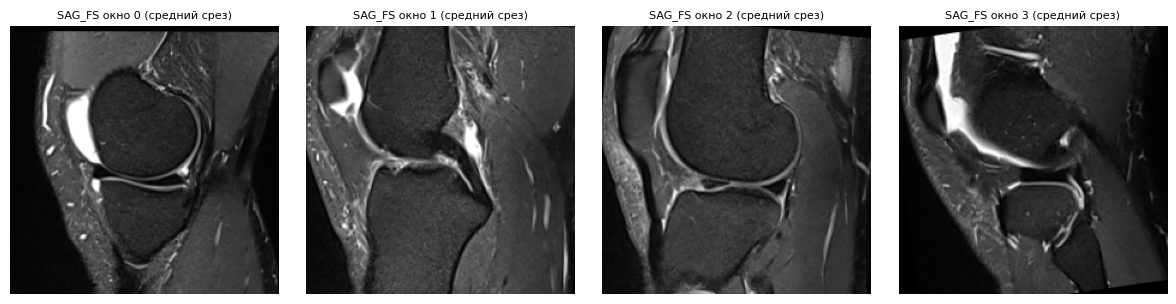

In [18]:
import importlib                                        # importlib.reload - перечитать модуль после правки

sys.path.insert(0, str(Path.cwd()))      # чтобы и ноутбук, и воркеры DataLoader нашли knee_dataset.py
import knee_dataset                                     # модуль из файла knee_dataset.py
importlib.reload(knee_dataset)           # после правки %%writefile подхватить новую версию
from knee_dataset import KneeStudyDataset, mirror_batch, N_SLOT, SAG_SLOTS  # нужные имена из модуля


def make_loader(idx, train, labels=None, weights=None):
    # DataLoader по строкам idx: обучение - случайные окна и аугментации, перемешивание; проверка - фиксированно
    # idx - номера строк train.csv; IDS[idx], labels[idx], weights[idx] берутся одними и теми же номерами
    ds = KneeStudyDataset(IDS[idx], STUDY_DIR,
                          labels=None if labels is None else labels[idx],
                          weights=None if weights is None else weights[idx],
                          train=train, k_windows=K_TRAIN if train else K_WIN, win_band=WIN_BAND,
                          fill_missing=FILL_MISSING_SLOTS, mirror_p=MIRROR_P, aug=AUG)
    return DataLoader(ds, batch_size=BATCH_STUDIES if train else EVAL_BATCH, shuffle=train,  # батч 8 или 4; перемешивать только при обучении
                      drop_last=train, num_workers=NUM_WORKERS,
                      persistent_workers=train and NUM_WORKERS > 0)   # воркеры обучения живут между эпохами


# Пример: одно исследование в режиме обучения и проверки
i0 = int(np.where(IDS == STUDY)[0][0])          # номер строки колена STUDY
for train in (True, False):                             # оба режима по очереди
    # .dataset[0] - вызвать __getitem__(0) напрямую, без DataLoader
    x, m, p, y, w = make_loader(np.array([i0]), train=train, labels=Y, weights=W).dataset[0]
    print(f"train={train}: x {tuple(x.shape)}, mask {m.tolist()}, pos[0] {p[0].numpy().round(2)}")  # формы и позиции окон ящика 0

# Что видит модель: окна сагиттальной серии в режиме обучения (с зеркалом и аугментациями)
x = KneeStudyDataset([STUDY], STUDY_DIR, train=True, k_windows=K_WIN, win_band=WIN_BAND, aug=AUG)[0][0]
# обратно из нормализации ImageNet в 0..1, чтобы показать: x * std + mean
img = (x * knee_dataset.IMAGENET_STD.view(1, 1, 3, 1, 1) + knee_dataset.IMAGENET_MEAN.view(1, 1, 3, 1, 1)).clamp(0, 1)
fig, axes = plt.subplots(1, K_WIN, figsize=(3 * K_WIN, 3))  # по картинке на окно
for j, ax in enumerate(axes):                           # j - номер окна
    # img[0, j, 1]: ящик 0 (SAG_FS), окно j, канал 1 = средний срез окна
    ax.imshow(img[0, j, 1], cmap="gray"); ax.axis("off"); ax.set_title(f"SAG_FS окно {j} (средний срез)", fontsize=8)
plt.tight_layout(); plt.show()                          # убрать наложения и показать

### 5.2 Путь одного колена по шагам и какие срезы берут окна

Таблица: для каждого из 6 ящиков - откуда взята серия (свой ящик или пара), сколько в ней срезов, центры
окон на проверке, сами окна (номера срезов) и `pos`.

Картинка: стопка срезов сагиттальной серии, слева направо срез 0 ... n-1. Строки:
- **проверка**: 4 фиксированных окна, одинаковые каждый раз;
- **обучение, эпоха 1-4**: 2 случайных окна, каждую эпоху другие. За 10 эпох окна проходят почти всю стопку.

Тёмная клетка - центр окна `c`, светлые - соседние срезы `c-1` и `c+1`.

In [ ]:
from knee_dataset import window_centres, FILL_PAIRS     # функция центров окон и пары ящиков

ds_demo = KneeStudyDataset([STUDY], STUDY_DIR, train=False, k_windows=K_WIN, win_band=WIN_BAND,  # датасет из одного колена, режим проверки
                           fill_missing=FILL_MISSING_SLOTS)
stacks = ds_demo.load_stacks(STUDY)                       # шаг 1: {номер ящика: [n, 224, 224]}
src = {k: k for k in stacks}                              # откуда взята серия каждого ящика
if FILL_MISSING_SLOTS:                                    # шаг 2: та же логика, что в __getitem__
    for a, b in FILL_PAIRS:                             # пары ящиков одной плоскости
        if a not in src and b in src:                   # первого нет, второй есть
            src[a] = b                                  # ящик a берёт серию из b
        elif b not in src and a in src:                 # наоборот
            src[b] = a                                  # ящик b берёт серию из a

rows = []                                               # строки таблицы
for k in range(N_SLOT):                                 # по 6 ящикам
    if k not in src:                                    # ящик пуст и после заполнения
        rows.append({"ящик": f"{k} {SLOT_NAMES[k]}", "откуда": "пусто, mask = 0"}); continue  # строка «пусто» и к следующему
    n = len(stacks[src[k]])                             # срезов в серии ящика
    c = window_centres(n, K_WIN, WIN_BAND)                # шаг 4 в режиме проверки
    rows.append({"ящик": f"{k} {SLOT_NAMES[k]}",        # строка таблицы для ящика k
                 "откуда": "свой" if src[k] == k else f"пара: {SLOT_NAMES[src[k]]}",
                 "срезов": n, "центры окон": c.tolist(),
                 "окна": [[int(j) - 1, int(j), int(j) + 1] for j in c],
                 "pos": np.round(c / (n - 1), 2).tolist()})
display(pd.DataFrame(rows))                             # показать таблицу

x, m, p, y, w = ds_demo[0]                                # всё вместе
print(f"итог __getitem__: x {tuple(x.shape)}, mask {m.tolist()}, pos {tuple(p.shape)}, y {tuple(y.shape)}, w {tuple(w.shape)}")  # формы всех пяти тензоров

# какие срезы берут окна: проверка и 4 «эпохи» обучения
k_sag = next((k for k in SAG_SLOTS if k in src), next(iter(src)))
n = len(stacks[src[k_sag]])                             # срезов в сагиттальной серии
layouts = [("проверка", window_centres(n, K_WIN, WIN_BAND))]  # центры окон на проверке
layouts += [(f"обучение, эпоха {e}", window_centres(n, K_TRAIN, WIN_BAND, np.random.default_rng(e))) for e in range(1, 5)]  # 4 «эпохи» со своим генератором случайностей
M = np.zeros((len(layouts), n))                         # таблица: строка = вариант, столбец = срез; 0 = не берём
for r_, (_, c) in enumerate(layouts):                   # r_ - номер строки, c - центры окон
    for j in c:                                         # по каждому центру
        M[r_, j - 1:j + 2] = np.maximum(M[r_, j - 1:j + 2], 1)   # соседние срезы окна
        M[r_, j] = 2                                             # центр окна
fig, ax = plt.subplots(figsize=(min(16, 0.45 * n + 3), 0.6 * len(layouts) + 1.2))  # ширина зависит от числа срезов
ax.imshow(M, cmap="Blues", vmin=0, vmax=2.4, aspect="auto")  # таблица как картинка: 0 белый, 1 голубой, 2 синий
ax.set_yticks(range(len(layouts))); ax.set_yticklabels([t for t, _ in layouts])  # подписи строк
ax.set_xticks(range(n)); ax.set_xticklabels(range(n), fontsize=7)  # номера срезов по горизонтали
ax.set_xlabel(f"номер среза в стопке {SLOT_NAMES[k_sag]} (всего {n})")  # подпись оси
lo_, hi_ = WIN_BAND[0] * (n - 1), WIN_BAND[1] * (n - 1)  # границы полосы в номерах срезов
for v in (lo_, hi_):                                    # обе границы
    ax.axvline(v, color="tab:red", lw=1, ls="--")                # полоса WIN_BAND
ax.set_title(f"окна в полосе {int(WIN_BAND[0] * 100)}-{int(WIN_BAND[1] * 100)}% (красные линии)", fontsize=10)  # заголовок
plt.tight_layout(); plt.show()                          # убрать наложения и показать

## 6. Модель: энкодер + «внимание по окнам» (MIL)

Колено - это «мешок» картинок: 6 ящиков × K окон. Метка дана на весь мешок, а не на конкретную картинку:
мы знаем, что в колене есть разрыв мениска, но не знаем, на каком окне он виден. Такая постановка называется
**MIL** (multiple instance learning, обучение на мешках).

```
каждое окно [3, 224, 224] ──► DINOv2 (энкодер) ──► вектор 384 ──► proj ──► вектор 256
          + «какой это ящик» (slot_emb: свой выученный вектор у каждого из 6 ящиков)
          + «где в колене окно» (pos_emb: маленькая сеть, число pos 0..1 -> вектор 256)
все окна колена ──► 1 слой трансформера (окна «видят» друг друга)
          ──► для КАЖДОЙ из 12 патологий своё внимание: веса по всем окнам (softmax, в сумме 1)
          ──► взвешенная сумма векторов окон ──► свой линейный классификатор ──► логит патологии
```

### Формы на одном шаге обучения (8 колен, K = 2)

| Где | Форма | Что |
|---|---|---|
| вход `x` | `[8, 6, 2, 3, 224, 224]` | 8 колен × 6 ящиков × 2 окна |
| в энкодер | `[~92, 3, 224, 224]` | только настоящие ящики (пустые пропускаем - экономия) |
| из энкодера | `[~92, 384]` | вектор на окно |
| после `proj` + эмбеддинги | `[8, 12, 256]` | 12 окон (6 × 2) на колено |
| внимание `a` | `[8, 12 окон, 12 патологий]` | вес каждого окна для каждой патологии |
| `pooled` | `[8, 12 патологий, 256]` | свой вектор колена для каждой патологии |
| выход | `[8, 12]` | логиты (сигмоида превратит в вероятности) |

**Зачем своё внимание каждой патологии.** Разрыв ACL виден на 1-2 сагиттальных окнах, артроз размазан по корональным.
Общее среднее размыло бы оба сигнала, а своё внимание позволяет каждой патологии «смотреть» туда, где её видно.

**Пустые ящики** не прогоняются через энкодер и исключаются из внимания маской (`pad`): им ставится -1e4 перед
softmax, и их вес становится 0.

**`load_backbone`** загружает веса со строгой проверкой: если ключи не совпали, будет ошибка.
**`set_trainable`** замораживает энкодер и размораживает последние `UNFREEZE_LAST` блоков.

В конце ячейки быстрая проверка: 2 случайных колена (у второго 4 пустых ящика) -> выход `[2, 12]` без NaN.

In [19]:
def load_backbone(name, weights_path, img):
    # Создаёт энкодер из библиотеки timm и загружает в него предобученные веса.
    # name: имя модели в timm, например "vit_small_patch14_dinov2.lvd142m"
    # weights_path: путь к .pth / None (скачать из интернета) / False (пустая сеть: веса придут из fold*.pth)
    # img: сторона входной картинки (224)
    kw = dict(num_classes=0)                # num_classes=0 -> сеть отдаёт вектор признаков, без головы
    if name.startswith(("vit_", "eva", "beit")):   # трансформеры для картинок
        kw["img_size"] = img                # у ViT позиционные эмбеддинги зависят от размера входа
    if weights_path is False:               # "is False", а не "not": None тоже «ложь», а его надо отличать
        return timm.create_model(name, pretrained=False, **kw)    # **kw раскрывает словарь в аргументы
    if weights_path and os.path.exists(weights_path):   # путь задан и файл есть
        m = timm.create_model(name, pretrained=False, **kw)      # архитектура со случайными весами
        sd = torch.load(weights_path, map_location="cpu", weights_only=False)   # state_dict: {имя слоя: тензор}
        for key in ("state_dict", "model"):               # бывают обёртки {"model": {...}}
            if isinstance(sd, dict) and key in sd and isinstance(sd[key], dict):  # внутри словаря лежит ещё словарь весов
                sd = sd[key]                              # снять обёртку
        # убираем приставки, которые добавляют обёртки при сохранении ("module.blocks.0..." -> "blocks.0...")
        sd = {k.removeprefix("module.").removeprefix("model."): v for k, v in sd.items()}
        # выкидываем старую голову-классификатор: у нас своя голова, а энкодер без головы (num_classes=0)
        sd = {k: v for k, v in sd.items() if not k.startswith(("head.fc.", "fc.", "classifier."))
              and not (k.startswith("head.") and name.startswith("vit_"))}
        if "pos_embed" in sd and hasattr(m, "pos_embed") and sd["pos_embed"].shape != m.pos_embed.shape:  # размер позиционных эмбеддингов не совпал
            # веса DINOv2 сохранены под 518px; под наш IMG интерполируем позиционные эмбеддинги
            # (518 / 14 = 37x37 кусочков-патчей, а у нас 224 / 14 = 16x16: «сетку мест» сжимаем до 16x16)
            from timm.layers import resample_abs_pos_embed
            sd["pos_embed"] = resample_abs_pos_embed(sd["pos_embed"], new_size=m.patch_embed.grid_size,  # пересчитать сетку под 16x16 патчей
                                                     num_prefix_tokens=m.num_prefix_tokens)   # служебные токены не трогать
        # strict=False + assert: сами проверяем, что ВСЕ ключи совпали. В бейзлайне 01 strict=False без проверки
        # молча пропустил бы несовпадение, и сеть училась бы со случайных весов.
        missing, unexpected = m.load_state_dict(sd, strict=False)   # каких ключей не хватило / какие лишние
        assert not missing and not unexpected, (        # все ключи совпали, иначе ошибка
            f"веса не подходят к {name}: missing={missing[:5]} unexpected={unexpected[:5]}")
        log(f"энкодер {name}: веса из файла, все ключи совпали")  # успех
        return m                                        # готовый энкодер с весами
    log(f"энкодер {name}: файла весов нет - скачиваю через timm (нужен Internet)")  # пойдём в интернет
    return timm.create_model(name, pretrained=True, **kw)    # pretrained=True: timm скачает веса сам


def set_trainable(bb, n_last):
    # всё заморозить, потом открыть «последнюю часть» сети
    # requires_grad = False: веса этого слоя не меняются при обучении (и не считается их градиент - быстрее)
    for p in bb.parameters():               # все тензоры весов энкодера
        p.requires_grad = False                         # заморозить
    if hasattr(bb, "blocks"):               # ViT: последние n_last блоков + финальная нормализация
        parts = list(bb.blocks)[-n_last:] + [getattr(bb, "norm", None)]   # [-6:] - последние 6
    elif hasattr(bb, "stages"):             # ConvNeXt и похожие CNN: две последние стадии + голова
        parts = list(bb.stages)[-2:] + [getattr(bb, "head", None), getattr(bb, "norm_pre", None)]  # две последние стадии CNN
    else:                                               # иначе
        parts = [bb]                        # неизвестная архитектура: учим всё
    for part in parts:                                  # по выбранным частям
        if part is not None:                # getattr(..., None) мог вернуть None
            for p in part.parameters():                 # их тензоры весов
                p.requires_grad = True      # эти веса учатся


class StudyMIL(nn.Module):
    # Модель «колено -> 12 логитов». Формы в комментариях даны для B = 8 колен, S = 6 ящиков, K = 2 окна.
    # nn.Module - базовый класс всех моделей PyTorch: слои в __init__, расчёт в forward
    def __init__(self, backbone=BACKBONE, weights=WEIGHTS_PATH, unfreeze_last=UNFREEZE_LAST,
                 hidden=HIDDEN, tf_depth=TF_DEPTH):
        super().__init__()                                        # обязательная инициализация nn.Module
        self.backbone = load_backbone(backbone, weights, IMG)     # DINOv2: картинка [3,224,224] -> вектор
        set_trainable(self.backbone, unfreeze_last)     # заморозить ранние блоки, открыть последние
        d = self.backbone.num_features                            # длина вектора энкодера: 384 у ViT-S
        # proj: вектор 384 -> вектор HIDDEN (256). Dropout(0.1) случайно зануляет 10% чисел при обучении
        # (против переобучения), LayerNorm выравнивает масштаб чисел.
        self.proj = nn.Sequential(nn.Dropout(0.1), nn.Linear(d, hidden), nn.LayerNorm(hidden))
        self.slot_emb = nn.Embedding(N_SLOT, hidden)            # «это сагиттальная FS» и т.п.: таблица 6 x 256
        # pos_emb: одно число pos (0..1) -> вектор 256 «где в колене это окно»; GELU - плавная нелинейность
        self.pos_emb = nn.Sequential(nn.Linear(1, hidden), nn.GELU(), nn.Linear(hidden, hidden))
        if tf_depth:                                              # 0 -> без трансформера
            # 1 слой трансформера: каждое окно «смотрит» на все остальные окна колена.
            # hidden=256 - размер векторов, 4 - головы внимания, hidden*2 - ширина внутреннего слоя
            # batch_first=True: вход [B, окна, 256]; norm_first=True: LayerNorm до внимания (стабильнее)
            layer = nn.TransformerEncoderLayer(hidden, 4, hidden * 2, dropout=0.1,
                                               batch_first=True, norm_first=True)
            self.tf = nn.TransformerEncoder(layer, tf_depth, enable_nested_tensor=False)   # tf_depth таких слоёв
        else:                                           # иначе
            self.tf = None                              # трансформер выключен
        # внимание: для каждого окна 12 чисел «насколько это окно важно для патологии c»
        self.att = nn.Sequential(nn.Linear(hidden, 128), nn.Tanh(), nn.Dropout(0.2),
                                 nn.Linear(128, len(TARGETS)))
        # nn.Parameter - обучаемый тензор. randn * 0.02 - маленькие случайные начальные веса
        self.cls_w = nn.Parameter(torch.randn(len(TARGETS), hidden) * 0.02)   # свой выход у каждой патологии
        self.cls_b = nn.Parameter(torch.zeros(len(TARGETS)))                   # сдвиг (bias) у каждой патологии

    def forward(self, x, mask, pos):
        # x: float [B, S, K, 3, H, W] (уже нормализован в Dataset)   mask: [B, S]   pos: [B, S, K]   ->   логиты [B, 12]
        B, S, K = x.shape[:3]                                  # 8, 6, 2
        keep = mask.reshape(-1) > 0.5                          # какие (исследование, слот) есть: [48] True/False
        feat = None                                     # векторы окон, заполним ниже
        if keep.any():                                         # есть хоть один настоящий ящик
            # [8,6,2,3,224,224] -> [48,2,3,224,224] -> только настоящие ящики, например [46,2,...]
            # -> flatten(0, 1) -> [92, 3, 224, 224]: обычный батч картинок для энкодера
            xs = x.reshape(B * S, K, *x.shape[3:])[keep].flatten(0, 1)   # только существующие картинки
            f = self.backbone(xs)                              # [n_картинок, d]: [92, 384]
            feat = f.new_zeros(B * S, K, f.shape[-1])          # [48, 2, 384] нулей (new_zeros: тот же тип и устройство)
            feat[keep] = f.view(-1, K, f.shape[-1])            # разложили векторы обратно по ящикам
        else:                                           # иначе
            feat = x.new_zeros((B * S, K, self.backbone.num_features))   # всё пусто: одни нули
        h = self.proj(feat.view(B, S, K, -1))                  # [8, 6, 2, 256]; -1 = «вычисли сам» (384)
        # + «какой это ящик»: вектор ящика [1, 6, 1, 256] прибавляется ко всем окнам ящика
        h = h + self.slot_emb(torch.arange(S, device=x.device)).view(1, S, 1, -1)   # arange(6) = [0..5]
        # + «где окно в колене»: pos [8, 6, 2] -> [8, 6, 2, 1] -> pos_emb -> [8, 6, 2, 256]
        h = h + self.pos_emb(pos.unsqueeze(-1).to(h.dtype))   # unsqueeze(-1) добавляет ось длины 1 в конец
        h = h.view(B, S * K, -1)                               # все окна исследования в одну «строку»: [8, 12, 256]
        pad = ~(mask > 0.5).unsqueeze(-1).expand(B, S, K).reshape(B, S * K)   # True = окна нет; ~ - логическое НЕ
        pad = pad & ~pad.all(1, keepdim=True)                  # исследование без серий: не маскируем всё
        if self.tf is not None:                         # трансформер включён
            h = self.tf(h, src_key_padding_mask=pad)           # окна обменялись информацией; пустые не слушаем
        # att(h): [8, 12 окон, 12 патологий]. Пустым окнам -1e4, чтобы после softmax их вес был 0.
        # softmax(1): по окнам. Для каждой патологии веса 12 окон в сумме дают 1.
        a = self.att(h).float().masked_fill(pad.unsqueeze(-1), -1e4).softmax(1)   # [B, окна, 12]
        # для каждой патологии c: взвешенная сумма векторов окон с её весами -> [8, 12 патологий, 256]
        # einsum "btc,btd->bcd": b - колено, t - окно, c - патология, d - число в векторе; сумма по t
        pooled = torch.einsum("btc,btd->bcd", a.to(h.dtype), h)                   # [B, 12, hidden]
        # у каждой патологии свой линейный классификатор: скалярное произведение с cls_w[c] + cls_b[c]
        return (pooled * self.cls_w).sum(-1) + self.cls_b


# ---- быстрая проверка формы на случайном входе ----
# 2 колена, у второго пусты ящики 2..5: модель должна вернуть [2, 12] конечных чисел
_m = StudyMIL().to(DEV).eval()                     # .to(DEV) - на видеокарту; .eval() - без Dropout
with torch.no_grad():                              # без градиентов: только прямой проход
    _x = torch.randn(2, N_SLOT, K_WIN, 3, IMG, IMG, device=DEV)   # случайные «картинки»
    _mk = torch.ones(2, N_SLOT, device=DEV); _mk[1, 2:] = 0       # у второго колена ящики 2..5 пустые
    _out = _m(_x, _mk, torch.rand(2, N_SLOT, K_WIN, device=DEV))  # вызов модели = forward
_tr = sum(p.numel() for p in _m.parameters() if p.requires_grad)  # numel - число элементов тензора
log(f"выход {tuple(_out.shape)}; обучаемых параметров {_tr / 1e6:.1f}M из "  # /1e6 - в миллионах
    f"{sum(p.numel() for p in _m.parameters()) / 1e6:.1f}M")
assert _out.shape == (2, len(TARGETS)) and torch.isfinite(_out).all()   # форма и нет NaN/inf
del _m, _out, _x                                   # удалить, чтобы освободить память видеокарты

[   10.2s] энкодер vit_small_patch14_dinov2.lvd142m: файла весов нет - скачиваю через timm (нужен Internet)
[   13.1s] выход (2, 12); обучаемых параметров 11.4M из 22.4M


## 7. Инструменты обучения

**`rank_loss`: тянет AUC напрямую.** AUC - это доля правильно упорядоченных пар «больной выше здорового».
Для каждой патологии берём в батче все пары (уверенно есть `y > 0.6`, уверенно нет `y < 0.4`) и штрафуем пару,
если «есть» получил оценку ниже: `softplus(-(z_есть - z_нет))`. Пример: `z_есть = 2, z_нет = -2` -> разница 4 ->
штраф ≈ 0.02; наоборот `z_есть = -2, z_нет = 2` -> разница -4 -> штраф ≈ 4.0.

**`Ema`: сглаженная копия модели.** После каждого шага: `ema = d·ema + (1 - d)·model`, `d = 0.997`. Получается
среднее весов примерно за последние 1 / (1 - 0.997) ≈ 330 шагов. Такая модель стабильнее, чем веса на одном шаге,
и именно её мы проверяем и сохраняем. В начале `d` меньше (разогрев), чтобы EMA не тащила случайные стартовые веса.

**`predict`**: проходит по `DataLoader` проверки и собирает вероятности. При `TTA_MIRROR` смотрит на колено дважды:
как есть и в зеркале (`mirror_batch`), и усредняет. Это TTA (test-time augmentation).

**`macro_auc`**: метрика соревнования. AUC по каждой цели, где есть оба класса, потом среднее.

Внизу самопроверки: зеркало, применённое дважды, должно вернуть исходник; rank_loss правильного порядка
должен быть меньше, чем неправильного.

In [20]:
def rank_loss(z, y, w):
    # z: логиты [B, 12], y: мягкие метки [B, 12], w: веса [B, 12]
    parts = []                                          # лоссы по каждой патологии
    for j in range(z.shape[1]):                                  # по 12 патологиям
        zp = z[(y[:, j] > RANK_POS) & (w[:, j] > 0), j]          # оценки колен, где патология уверенно ЕСТЬ
        zn = z[(y[:, j] < RANK_NEG) & (w[:, j] > 0), j]          # оценки колен, где уверенно НЕТ
        if len(zp) and len(zn):                         # есть и «есть», и «нет»
            # zp[:, None] - zn[None, :]: таблица разниц всех пар [n_есть, n_нет]; хотим, чтобы все были > 0
            parts.append(F.softplus(-(zp[:, None] - zn[None, :])).mean())
    return torch.stack(parts).mean() if parts else z.new_tensor(0.0)  # среднее по патологиям; пар нет -> 0


class Ema:
    def __init__(self, model, decay):                   # создать EMA-копию модели
        self.decay, self.step = decay, 0                # коэффициент сглаживания и счётчик шагов
        self.model = deepcopy(model).eval()          # отдельная копия модели
        for p in self.model.parameters():               # по весам копии
            p.requires_grad_(False)                  # её не учим напрямую, только усредняем

    @torch.no_grad()
    def update(self, model):                            # обновить копию после шага обучения
        self.step += 1                                  # +1 шаг
        d = min(self.decay, (1.0 + self.step) / (10.0 + self.step))   # разогрев: сначала быстро
        src = model.state_dict()                        # текущие веса обучаемой модели
        for k, v in self.model.state_dict().items():    # по весам копии: имя k, тензор v
            if v.dtype.is_floating_point:               # дробные веса усредняем
                v.mul_(d).add_(src[k].detach(), alpha=1.0 - d)        # ema = d * ema + (1 - d) * model
            else:                                       # иначе
                v.copy_(src[k])                                       # целые буферы просто копируем


@torch.no_grad()
def predict(model, loader, tta_mirror=TTA_MIRROR):
    # -> вероятности [число исследований в loader, 12] в порядке loader (shuffle=False)
    # @torch.no_grad() - декоратор: вся функция без градиентов -> меньше памяти и быстрее
    model.eval()                 # выключает Dropout: на проверке модель должна отвечать одинаково
    out = []                                # сюда складываем вероятности батчей
    for x, m, p, _, _ in loader:            # метки и веса (_, _) здесь не нужны
        x, m, p = x.to(DEV), m.to(DEV), p.to(DEV)   # на видеокарту
        with torch.autocast(DEV.type, dtype=AMP_DTYPE, enabled=USE_AMP):   # float16, если включено
            prob = torch.sigmoid(model(x, m, p).float())     # логиты -> вероятности 0..1
            if tta_mirror:                                 # второй взгляд: зеркальное колено
                xm, pm = mirror_batch(x, p)                # отражённый батч
                prob = 0.5 * (prob + torch.sigmoid(model(xm, m, pm).float()))   # среднее двух взглядов
        out.append(prob.cpu().numpy())                     # на CPU и в numpy
    return np.concatenate(out) if out else np.zeros((0, 12), np.float32)   # склеить батчи в одну таблицу


def macro_auc(y, p):
    # метрика соревнования: среднее AUC по колонкам, где есть оба класса
    return float(np.nanmean([roc_auc_score(y[:, j], p[:, j]) if 0 < y[:, j].sum() < len(y)
                             else np.nan for j in range(y.shape[1])]))


# самопроверки
_x = torch.arange(N_SLOT * 2 * 3 * 2 * 2, dtype=torch.float32).view(1, N_SLOT, 2, 3, 2, 2)
_p = torch.tensor([[[0.1, 0.9]] * N_SLOT])              # позиции 0.1 и 0.9 в каждом ящике
_xm, _pm = mirror_batch(*mirror_batch(_x, _p))          # зеркало дважды; * раскрывает пару (x, pos) в два аргумента
assert torch.equal(_xm, _x) and torch.allclose(_pm, _p), "зеркало дважды должно давать исходник"  # equal - точно равны, allclose - почти равны
assert rank_loss(torch.tensor([[2.], [-2.]]), torch.tensor([[1.], [0.]]), torch.ones(2, 1)) < \
       rank_loss(torch.tensor([[-2.], [2.]]), torch.tensor([[1.], [0.]]), torch.ones(2, 1))  # неправильный порядок: больной ниже здорового
log("mirror_batch и rank_loss прошли самопроверку")     # всё в порядке

[   13.2s] mirror_batch и rank_loss прошли самопроверку


## 8. Обучение

### Две метрики после каждой эпохи

- **`derived`**: macro-AUC на валидационном фолде (~1100 колен) против меток из текста (`Y > 0.5`). Много колен,
  но метки сами с ошибками экстрактора;
- **`gold`**: macro-AUC на **58** вручную размеченных (в обучении не участвуют). Ближе всего к лидерборду, но шумнее.

**Лучшая эпоха** выбирается по `min(derived, gold)`: модель должна быть хороша по обеим. Её веса (EMA) сохраняются.

### Один шаг обучения

| # | Строка | Что делает |
|---|---|---|
| 1 | `for x, m, p, y, w in train_loader` | батч от `DataLoader`: воркеры уже выбрали окна и сделали аугментации |
| 2 | `.to(DEV)` | перенос на видеокарту |
| 3 | `torch.autocast(...)` | считать в float16 там, где это безопасно (в 1.5 раза быстрее на MPS) |
| 4 | `z = model(x, m, p)` | 12 логитов на колено |
| 5 | `BCE(z, y) * w` | ошибка по каждой метке, умноженная на её вес; тишина весит мало |
| 6 | `+ RANK_LOSS_W * rank_loss` | плюс штраф за неправильный порядок пар |
| 7 | `scaler.scale(loss).backward()` | градиенты. `GradScaler` умножает лосс на большое число, чтобы маленькие градиенты не обнулились в float16 |
| 8 | `scaler.step(opt)`, `scaler.update()` | шаг AdamW (с обратным делением) и подстройка множителя |
| 9 | `sched.step()` | шаг расписания LR |
| 10 | `ema.update(model)` | обновить сглаженную копию |

### Оптимизатор и расписание

- `AdamW` с двумя группами параметров: энкодер (`LR_BACKBONE = 8e-6`) и голова (`LR_HEAD = 5e-4`, в ~60 раз больше);
- `OneCycleLR`: первые 15% шагов LR растёт от малого до максимума (разогрев: голова ещё случайная, большие шаги
  испортили бы энкодер), потом плавно падает почти до нуля к концу обучения.

После всех эпох в модель загружаются лучшие веса, и она предсказывает 58 размеченных (для ансамбля фолдов).

In [21]:
GOLD_LOADER = make_loader(GOLD_IDX, train=False, labels=Y_GOLD)   # одинаковый для всех фолдов


def train_fold(k):                                      # обучить модель фолда k; вернуть модель, веса, предсказания gold и историю
    tr = TRAINABLE[FOLD[TRAINABLE] != k]           # строки обучения: все фолды, кроме k
    va = TRAINABLE[FOLD[TRAINABLE] == k]           # строки проверки: фолд k
    yv = (Y[va] > 0.5).astype(int)                 # метки проверки для derived: мягкие -> 0/1
    log(f"=== фолд {k}: учимся на {len(tr)}, проверяем на {len(va)} (+ {len(GOLD_IDX)} размеченных) ===")  # размеры частей
    assert len(tr) >= BATCH_STUDIES and len(va) > 0, "пустой фолд - проверьте FOLD"  # части не пустые
    train_loader = make_loader(tr, train=True, labels=Y, weights=W)  # батчи обучения
    val_loader = make_loader(va, train=False, labels=Y, weights=W)  # батчи проверки

    seed_everything(SEED + k)                      # у каждого фолда своё, но повторяемое зерно
    model = StudyMIL().to(DEV)                          # новая модель на видеокарте
    ema = Ema(model, EMA_DECAY) if EMA_DECAY > 0 else None  # сглаженная копия (или без неё)
    # две группы параметров: обучаемые блоки энкодера и вся голова (всё, что не начинается с "backbone.")
    bb_params = [p for p in model.backbone.parameters() if p.requires_grad]
    head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]  # named_parameters - пары (имя, тензор)
    opt = torch.optim.AdamW([{"params": bb_params, "lr": LR_BACKBONE},  # две группы со своими LR
                             {"params": head_params, "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
    # total_steps = эпохи × батчей в эпохе: расписание знает, когда обучение закончится
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_BACKBONE, LR_HEAD],
                                                total_steps=EPOCHS * len(train_loader), pct_start=PCT_START)
    scaler = torch.amp.GradScaler(DEV.type, enabled=USE_AMP)  # масштаб лосса для float16

    best, best_state, hist = -1.0, None, []             # лучший счёт, его веса, история эпох
    for ep in range(EPOCHS):                            # ep = 0..9
        model.train()                              # включить Dropout
        tot, n, t_ep = 0.0, 0, time.time()              # сумма лоссов, число шагов, время начала эпохи
        for x, m, p, y, w in train_loader:              # батч: картинки, маска, позиции, метки, веса
            # non_blocking=True: копирование на видеокарту не ждёт окончания, пока можно готовить следующее
            x, m, p, y, w = (t.to(DEV, non_blocking=True) for t in (x, m, p, y, w))
            with torch.autocast(DEV.type, dtype=AMP_DTYPE, enabled=USE_AMP):  # внутри блока float16, где безопасно
                z = model(x, m, p)                 # логиты [8, 12]
                # reduction="none": ошибка по каждой метке отдельно [8, 12] -> * веса -> среднее
                loss = (F.binary_cross_entropy_with_logits(z.float(), y, reduction="none") * w).mean()
                if RANK_LOSS_W > 0:                     # ranking loss включён
                    loss = loss + RANK_LOSS_W * rank_loss(z.float(), y, w)  # добавить его с весом 0.05
            opt.zero_grad(set_to_none=True)        # обнулить градиенты прошлого шага
            scaler.scale(loss).backward()               # градиенты от увеличенного лосса
            scaler.step(opt)                            # шаг оптимизатора (градиенты делятся обратно)
            scaler.update()                             # подстроить множитель
            sched.step()                                # шаг расписания LR
            if ema is not None:                         # EMA включена
                ema.update(model)                       # обновить сглаженную копию
            tot += loss.item(); n += 1                  # копим лосс и число шагов

        # проверка: EMA-модель на фолде (без зеркала - быстрее) и на 58 размеченных (с зеркалом)
        ev = ema.model if ema is not None else model
        d = macro_auc(yv, predict(ev, val_loader, tta_mirror=False))  # derived: AUC на фолде против меток из текста
        g = macro_auc(Y_GOLD[GOLD_IDX].astype(int), predict(ev, GOLD_LOADER))  # gold: AUC на 58 размеченных
        score = min(d, g)                               # счёт эпохи = худшая из двух метрик
        hist.append({"fold": k, "epoch": ep + 1, "loss": tot / max(n, 1), "derived": d, "gold": g})  # строка истории
        flag = ""                                       # пометка «лучшая» пока пустая
        if score > best:                                # новый рекорд
            best, flag = score, "  <- лучшая"           # запомнить счёт и пометку
            # копия весов на CPU: следующая эпоха их не изменит
            best_state = {kk: v.detach().cpu().clone() for kk, v in ev.state_dict().items()}
        log(f"фолд {k} эпоха {ep + 1}/{EPOCHS}  loss {tot / max(n, 1):.4f}  derived {d:.4f}  "  # строка лога эпохи
            f"gold {g:.4f}  ({time.time() - t_ep:.0f}s){flag}")

    model.load_state_dict(best_state)              # вернуть лучшие веса
    gold_pred = predict(model, GOLD_LOADER)             # предсказания лучших весов на 58 размеченных
    del opt, sched, scaler, ema, train_loader, val_loader  # удалить большие объекты, освободить память
    return model, best_state, gold_pred, hist           # четыре результата

### Запуск: все фолды из `FOLDS_TO_RUN`

Для каждого фолда: обучить, сохранить `outputs/weights/fold{k}.pth`, освободить память.

В файл весов кроме самих весов (`"model"`) кладётся `"config"`: энкодер, `IMG`, `CROP_MM`, `MAX_SLICES`, окна и
размеры головы. `04_kaggle_submission.ipynb` читает их оттуда и готовит test ровно так же, как готовились данные
при обучении.

В конце: предсказания фолдов на 58 размеченных переводятся в **ранги** (`rank(pct=True)`: место среди 58, от 0 до 1)
и усредняются. Ранги, а не вероятности: у разных моделей разный масштаб уверенности, а AUC важен только порядок.
Плюс таблица gold AUC по каждой цели и графики метрик по эпохам.

[   13.3s] === фолд 0: учимся на 3276, проверяем на 1073 (+ 58 размеченных) ===
[   13.3s] энкодер vit_small_patch14_dinov2.lvd142m: файла весов нет - скачиваю через timm (нужен Internet)


[ 3451.7s] фолд 0 эпоха 1/10  loss 0.3841  derived 0.7132  gold 0.7140  (3438s)  <- лучшая
[18526.4s] фолд 0 эпоха 2/10  loss 0.3689  derived 0.7486  gold 0.7546  (15075s)  <- лучшая
[19040.1s] фолд 0 эпоха 3/10  loss 0.3605  derived 0.7756  gold 0.7779  (514s)  <- лучшая
[19569.5s] фолд 0 эпоха 4/10  loss 0.3557  derived 0.7848  gold 0.7862  (529s)  <- лучшая
[20059.9s] фолд 0 эпоха 5/10  loss 0.3509  derived 0.7900  gold 0.7978  (490s)  <- лучшая
[20739.2s] фолд 0 эпоха 6/10  loss 0.3472  derived 0.7938  gold 0.8073  (679s)  <- лучшая
[21228.4s] фолд 0 эпоха 7/10  loss 0.3439  derived 0.7954  gold 0.8120  (489s)  <- лучшая
[21546.3s] фолд 0 эпоха 8/10  loss 0.3401  derived 0.7971  gold 0.8092  (318s)  <- лучшая
[21863.7s] фолд 0 эпоха 9/10  loss 0.3368  derived 0.7988  gold 0.8100  (317s)  <- лучшая
[22162.6s] фолд 0 эпоха 10/10  loss 0.3356  derived 0.7999  gold 0.8091  (299s)  <- лучшая
[22229.5s] фолд 0 готов за 370.3 мин -> /Users/admin/Desktop/kaggle-deep-learning/rsna-knee-abno

,gold AUC по целям
ACL,0.815
MCL,0.683
Medial Meniscus,0.708
Lateral Meniscus,0.788
Medial OA,0.919
Lateral OA,0.805
PF OA,0.731
Effusion,0.876
Synovitis,0.705
Baker's,0.884


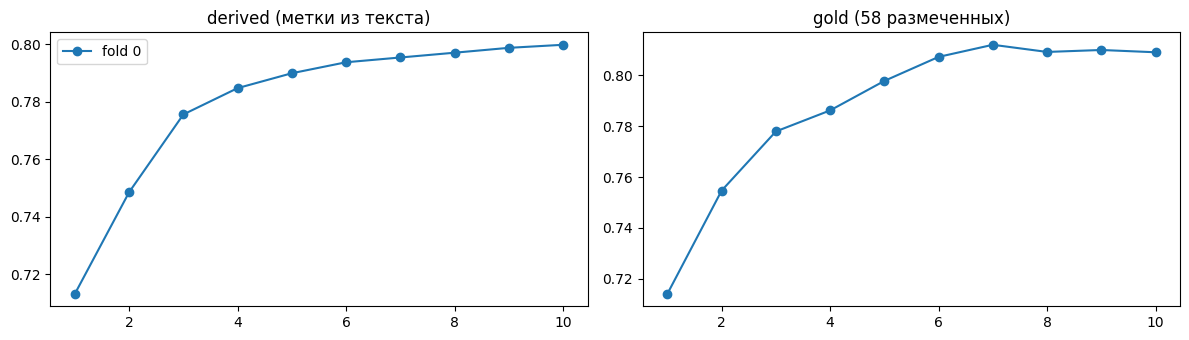

In [22]:
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)          # создать папку весов, если её нет
HIST, GOLD_PREDS = [], []                               # история и предсказания всех фолдов
for k in FOLDS_TO_RUN:                                  # по выбранным фолдам
    t_fold = time.time()                                # засечь время
    model, state, gp, hist = train_fold(k)              # обучить фолд
    HIST += hist                                        # добавить его историю
    GOLD_PREDS.append(pd.DataFrame(gp).rank(pct=True).values)   # вероятности -> ранги 0..1
    torch.save({"model": state, "config": {"BACKBONE": BACKBONE, "IMG": IMG, "CROP_MM": CROP_MM,  # веса + настройки в один файл
                "MAX_SLICES": MAX_SLICES, "K_WIN": K_WIN, "WIN_BAND": list(WIN_BAND), "FILL_MISSING_SLOTS": FILL_MISSING_SLOTS, "UNFREEZE_LAST": UNFREEZE_LAST,
                "HIDDEN": HIDDEN, "TF_DEPTH": TF_DEPTH}}, WEIGHTS_DIR / f"fold{k}.pth")
    fold_time = time.time() - t_fold                    # сколько секунд шёл фолд
    log(f"фолд {k} готов за {fold_time / 60:.1f} мин -> {WEIGHTS_DIR / f'fold{k}.pth'}")  # куда сохранили
    del model, state                                    # освободить память
    gc.collect(); empty_device_cache()            # освободить память перед следующим фолдом

y_gold = Y_GOLD[GOLD_IDX].astype(int)                   # ручные метки 58 колен, 0/1
ens = np.mean(GOLD_PREDS, axis=0)                 # среднее рангов всех фолдов
log(f"ансамбль {len(GOLD_PREDS)} фолд(ов) на {len(GOLD_IDX)} размеченных: gold macro-AUC = {macro_auc(y_gold, ens):.4f}")  # итоговая метрика
per_t = [roc_auc_score(y_gold[:, j], ens[:, j]) if 0 < y_gold[:, j].sum() < len(y_gold) else np.nan  # AUC по каждой цели
         for j in range(len(TARGETS))]
display(pd.Series(per_t, index=TARGETS, name="gold AUC по целям").round(3).to_frame())  # таблица AUC по целям

h = pd.DataFrame(HIST)                                  # история эпох таблицей
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))         # два графика рядом
for f_, gdf in h.groupby("fold"):                       # по фолдам: номер и его строки
    ax[0].plot(gdf.epoch, gdf.derived, "o-", label=f"fold {f_}")  # "o-" - точки, соединённые линией
    ax[1].plot(gdf.epoch, gdf.gold, "o-", label=f"fold {f_}")  # то же для gold
ax[0].set_title("derived (метки из текста)"); ax[1].set_title("gold (58 размеченных)")  # заголовки графиков
ax[0].legend(); plt.tight_layout(); plt.show()          # легенда и показать

### 8.1 Разбор первого прогона (фолд 0, 10 эпох)

| Эпоха | loss | derived | gold | Время |
|---|---|---|---|---|
| 1 | 0.384 | 0.713 | 0.714 | 57 мин |
| 2 | 0.369 | 0.749 | 0.755 | 4 ч 11 мин |
| 3 | 0.361 | 0.776 | 0.778 | 8.6 мин |
| 5 | 0.351 | 0.790 | 0.798 | 8.2 мин |
| 7 | 0.344 | 0.795 | **0.812** | 8.2 мин |
| 10 | 0.336 | 0.800 | 0.809 | 5.0 мин |

Что видно:

1. **Метки из текста работают**: с 0.64 у бейзлайна до 0.81 на тех же 58 коленах.
2. `derived` и `gold` растут вместе и почти равны: модель учится тому, что действительно есть на снимках,
   а не подстраивается под экстрактор.
3. Лучшей помечена 10-я эпоха, хотя `gold` был выше на 7-й (0.812): выбор идёт по `min(derived, gold)`,
   а `derived` рос до конца. Разница 0.003 - это шум 58 колен.
4. **Время**: обычная эпоха занимает 5-11 минут. Эпохи 1-2 шли 57 минут и 4 часа - скорее всего Mac уходил в сон
   или был занят. Для долгого обучения запустите в терминале команду, которая не даёт Mac заснуть, пока она работает
   (закройте её Ctrl+C после обучения):

```bash
caffeinate -dims
```

## 9. Что дальше

### Сабмит

1. Веса лежат в `outputs/weights/fold*.pth`. Загрузите эту папку на Kaggle как датасет
   (Datasets -> New Dataset), например `rsna-knee-folds-vits`.
2. Откройте на Kaggle `04_kaggle_submission.ipynb`, подключите соревнование и этот датасет, включите GPU, нажмите Submit.
   Настройки картинок и модели он прочитает прямо из файлов весов.

### Улучшения по одному за раз

| # | Что | Как | Ожидание |
|---|---|---|---|
| 1 | **LLM-таблицы меток** | CSV в `data/llm_labels/` (раздел 3.2) | самый большой прирост: потолок модели - качество меток |
| 2 | **Все фолды** | `FOLDS_TO_RUN = [0, 1, 2, 3]` | ансамбль из 4 моделей, обычно +0.01-0.02 |
| 3 | **Второй энкодер** | `BACKBONE = "vit_base_patch14_dinov2.lvd142m"`, веса в отдельную папку | разные архитектуры ошибаются по-разному; 04 усредняет ранги всех весов |
| 4 | **Больше окон** | `K_WIN = 6`, `K_TRAIN = 3` | срезы уже в кэше, пересобирать ничего не нужно |

**Чего не делать:** вертикальный флип (бедро <-> голень), label smoothing (метки уже мягкие),
`pos_weight` и пороги (AUC от них не зависит).